# Higgs-portal homebrew shard validation

Read-only checks of the published homebrew hits, cells and particles: **100 events per pileup setting** by default. Pu0 is **blue**, pu200 **green**. The two settings use independent hard-scatter event selections; matching local IDs do not imply the same LLP event. The saved production report validates all 200 pu200 LLP decay endpoints.

Use **Restart Kernel and Run All** after changing paths. Existing saved outputs may describe the earlier one-event pilot until rerun. The full scan checks every event sequentially; only small count/coverage tables and flagged-hit rows are retained. No ACTS, Docker, PyTorch, ROOT inputs or further downloads are needed. These checks do not establish tracking efficiency or detector resolution.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "notebooks/validation/higgs_portal_validation.py").is_file())
sys.path.insert(0, str(REPO))
from notebooks.validation import higgs_portal_validation as validation
from notebooks.validation import paired_vs_published as paired

PAIRED_ROOT = Path("/mnt/data2/data/collider_ml/homebrew/higgs_portal_v2_cells")
# Alternatively: PAIRED_ROOT = REPO.parent / "exports/higgs-portal-pilot-run1-n1/paired"
EVENT = 0  # Detailed feature distributions, cells and galleries.
PREVIEW_EVENTS = (0, 24, 99)  # Lightweight spatial checks; no cell frames loaded.
RUN_FULL_SHARD_SCAN = True  # All 100 events, read sequentially. Can take several minutes.
PARTICLE_COHORT = "generator_charged_with_hits"
SCATTER_LIMIT = 15000
SEED = 7
GALLERY_SAMPLE = "pu200"
CLUSTER_TARGET_SIZES = (1, 2, 4, 8, 16, 32)
CHECK_SOURCE_HASHES = True

# Optional historical one-event numerical reference; unavailable for the new shard.
RUN_PERIGEE_REFERENCE = False
REFERENCE_PILOT_ROOT = REPO.parent / "exports/higgs-portal-pilot-run1-n1"
BASELINE_PAIRED_ROOT = REFERENCE_PILOT_ROOT / "paired.before-recovery-v2"
PERIGEE_VALIDATION_ROOT = REFERENCE_PILOT_ROOT / "validation/perigee_reference"

pd.set_option("display.max_columns", 30)
print("Parquet release being tested:", PAIRED_ROOT)
print("Selected local event:", EVENT, "in each independent sample")
print("Spatial preview events:", PREVIEW_EVENTS)
print("Full-shard validation enabled:", RUN_FULL_SHARD_SCAN)
before_hashes = validation.file_hashes(PAIRED_ROOT) if CHECK_SOURCE_HASHES else None

Parquet release being tested: /mnt/data2/data/collider_ml/homebrew/higgs_portal_v2_cells
Selected local event: 0 in each independent sample
Spatial preview events: (0, 24, 99)
Full-shard validation enabled: True


## Production evidence and event selection

Check completion markers and inspect the simulation gate and recovery provenance. The published pu0 ROOT input was already simulated; only pu200 was newly simulated in this pilot. LLP endpoint checks below concern that new pu200 simulation.

Particle `vx/vy/vz` are **production vertices**, not decay endpoints. An LLP's own production vertex should be near its collision vertex. Displaced daughter production vertices, perigee parameters, and the saved simulation endpoint check provide complementary evidence. `vertex_primary` is an event-local vertex identifier, not a boolean or guaranteed signal tag.

In [2]:
pilot, complete, simulation_check = validation.production_evidence(PAIRED_ROOT)
display(pd.Series(pilot["physics"], name="Physics point").to_frame())
display(pd.Series({key: value for key, value in simulation_check.items()
                   if not isinstance(value, (list, dict))}, name="Simulation validation").to_frame())
display(pd.DataFrame(pilot["selected_signal_events"]).head(10))
if simulation_check.get("root_to_hepmc"):
    print("pu200 local-event to generator-event mapping (first ten entries):")
    display(pd.DataFrame(simulation_check["root_to_hepmc"]).rename(columns={"root_entry": "local_event"}).head(10))
print("Event pairing:", pilot["comparison_note"])
print("Release event count:", complete["events_per_sample"], "per setting; production run", pilot["run"])
print("Original source and validation checksums are in the provenance directory.")
boost_matches = pd.DataFrame(simulation_check.get("decay_boost_matches", []))
if not boost_matches.empty:
    display(boost_matches.head(20))

,Physics point
higgs_mass_GeV,125.0
llp_mass_GeV,55.0
llp_ctau_mm,100.0
llp_pdg,36
decay,h -> aa -> b bbar b bbar


,Simulation validation
events,100
llps_checked,200
validation_algorithm,ancestry-decay-boost-v1
decay_boost_match_count,68
maximum_decay_boost_relative_residual,0.000024
decay_boost_relative_residual_tolerance,0.001
decay_boost_vertex_tolerance_mm,0.0001
passed,True
maximum_llp_endpoint_error_mm,0.0
charged_descendants_checked,3690


,source_entry,source_event_number,logical_event
0,0,0,0
1,1,1,1
2,2,2,2
3,3,3,3
4,4,4,4
5,5,5,5
6,6,6,6
7,7,7,7
8,8,8,8
9,9,9,9


pu200 local-event to generator-event mapping (first ten entries):


,local_event,hepmc_event
0,0,24
1,1,9
2,2,4
3,3,1
4,4,21
5,5,0
6,6,20
7,7,23
8,8,5
9,9,22


Event pairing: pu0 ROOT entries and pu200 signal selections are not assumed event-by-event paired
Release event count: 100 per setting; production run 3
Original source and validation checksums are in the provenance directory.


,event,root_entry,hepmc_id,pdg,mcparticle,parent_hepmc_id,parent_mcparticle,parent_pdg,original_relative_momentum_difference,predicted_relative_momentum_residual,daughter_to_parent_endpoint_error_mm
0,24,0,1450,22,1449,1414,1413,111,0.001146,4.196347e-07,0.0
1,12,12,2173,111,2172,2164,2163,3222,0.010592,8.169835e-06,0.0
2,12,12,2187,22,2186,2173,2172,111,0.014393,7.217736e-06,0.0
3,12,12,2186,22,2185,2173,2172,111,0.007759,7.140409e-06,0.0
4,12,12,2172,2212,2171,2164,2163,3222,0.013177,9.356078e-07,0.0
5,13,19,1252,22,1251,1224,1223,111,0.001981,3.648780e-06,0.0
6,13,19,1273,211,1272,1251,1250,310,0.001015,3.003384e-06,0.0
7,3,21,1981,211,1980,1960,1959,3222,0.001544,4.173083e-09,0.0
8,3,21,1980,2112,1979,1960,1959,3222,0.001541,8.326684e-08,0.0
9,7,23,772,-211,771,740,739,3312,0.004271,1.868097e-07,0.0


## Counts, schemas and associations

Loads only the selected event. Particle files are event-row/list-column tables, whereas hits and cells have one row per measurement or cell. Checks use the full measurement key:
`(campaign, dataset, version, run, local_event, measurement_id)`.

Every cell must have exactly one parent hit with the same geometry; every hit must have cells. Particle references and scalar labels are checked against this event's particles. Null scalar labels are permitted for multi-particle hits; contributor lists remain authoritative. Legacy converted-label disagreements and incomplete truth are reported separately, not hidden.

In [3]:
samples = validation.load_samples(PAIRED_ROOT, EVENT)
analyses = {name: sample.analysis for name, sample in samples.items()}
checks = validation.integrity(samples)
display(checks)
display(validation.coverage(samples))
display(pd.DataFrame([
    dict(sample=name, measurements=sample.hits.num_rows, cells=sample.cells.num_rows,
         particles=len(sample.particles), particle_memory_MiB=sample.particles.memory_usage(deep=True).sum()/2**20,
         cell_analysis_memory_MiB=sample.analysis.cells.memory_usage(deep=True).sum()/2**20)
    for name, sample in samples.items()
]))
display(pd.concat([validation.truth_review(sample, limit=20) for sample in samples.values()], ignore_index=True))
print("Incomplete particle_ids are lower bounds; legacy converted labels are comparison diagnostics.")

,event,measurements,cells,particles,simhit_links,null_particle_labels,multi_particle_measurements,unresolved_simhit_links,incomplete_truth_measurements,converted_label_disagreements,orphan_cells,hits_without_cells,missing_parent_ids,association_checks
sample,,,,,,,,,,,,,,
pu0,0,2910,15126,2908,3026,71,71,0,0,0,0,0,0,PASS
pu200,0,181661,855750,215473,188688,5117,5117,2,1,0,0,0,0,PASS


,sample,table,feature,dtype,role
0,pu0,hits,campaign,string,identifier / integrity
1,pu0,hits,dataset,string,identifier / integrity
2,pu0,hits,version,string,identifier / integrity
3,pu0,hits,run,uint32,identifier / integrity
4,pu0,hits,local_event,uint32,identifier / integrity
...,...,...,...,...,...
93,pu200,particles,primary,list<element: bool>,distribution / missingness
94,pu200,particles,vertex_primary,list<element: uint16>,distribution / missingness
95,pu200,particles,parent_id,list<element: int64>,identifier / integrity
96,pu200,particles,perigee_d0,list<element: float>,distribution / missingness


,sample,measurements,cells,particles,particle_memory_MiB,cell_analysis_memory_MiB
0,pu0,2910,15126,2908,0.274677,6.006024
1,pu200,181661,855750,215473,20.343738,338.982292


,campaign,dataset,version,run,local_event,measurement_id,particle_id,converted_particle_id,particle_ids,particle_ids_complete,unresolved_simhit_ids,simhit_ids,issue,sample
0,full_pileup,higgs_portal,v2_cells_pilot,3,0,133721,NaN,NaN,"[83305, 83311, 83310]",False,"[138447, 138448]","[138446, 138447, 138448, 138449, 138451]",incomplete contributor truth,pu200


Incomplete particle_ids are lower bounds; legacy converted labels are comparison diagnostics.


## Missing and non-finite values

The table counts both nulls and NaN/infinity. Some perigee values are undefined, particularly for neutral particles or particles without a useful tracker trajectory. Null strip `pixel_code` values are intentional. These populations must not be silently filled or treated as pixel-encoding failures.

,sample,table,feature,entries,nonfinite,fraction
17,pu0,particles,perigee_d0,2908,1307,0.449450
18,pu0,particles,perigee_z0,2908,1307,0.449450
22,pu0,particles,eta,2908,7,0.002407
32,pu0,hits,particle_id,2910,71,0.024399
33,pu0,hits,converted_particle_id,2910,85,0.029210
36,pu0,cells,pixel_code,15126,8536,0.564326
54,pu200,particles,perigee_d0,215473,83128,0.385793
55,pu200,particles,perigee_z0,215473,83128,0.385793
59,pu200,particles,eta,215473,1310,0.006080
69,pu200,hits,particle_id,181661,5117,0.028168


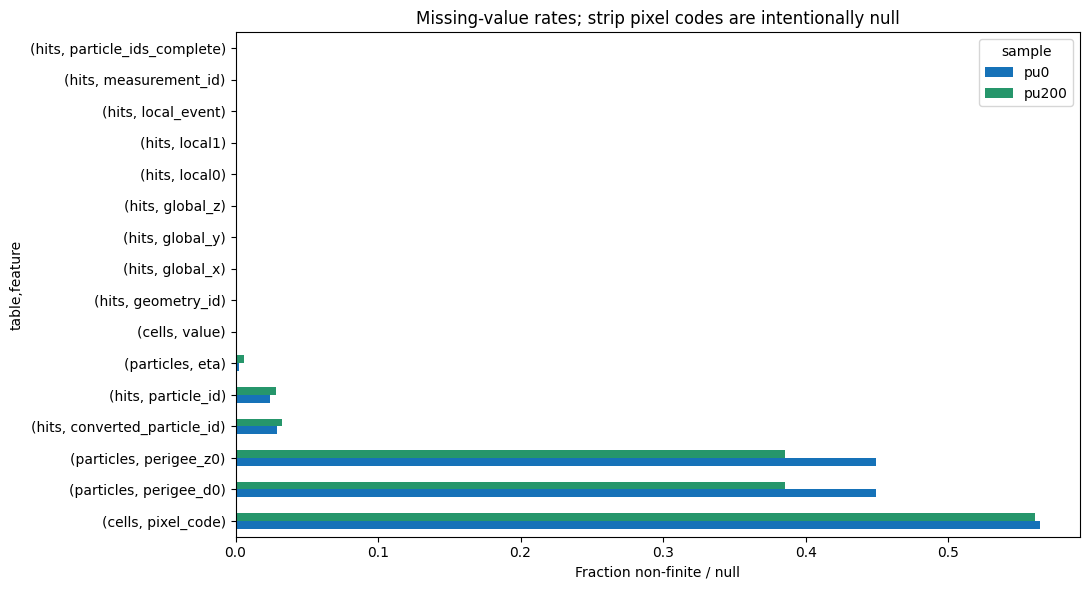

,sample,cohort,particles,finite_d0,finite_z0
0,pu0,all,2908,1601,1601
1,pu0,generator_charged_with_hits,125,124,124
2,pu0,charged_with_hits,619,284,284
3,pu0,displaced_charged_with_hits,530,195,195
4,pu200,all,215473,132345,132345
5,pu200,generator_charged_with_hits,7356,7355,7355
6,pu200,charged_with_hits,39396,16438,16438
7,pu200,displaced_charged_with_hits,32444,9487,9487


In [4]:
nonfinite = validation.nonfinite_rates(samples)
display(nonfinite[nonfinite.nonfinite > 0])
rates = nonfinite.pivot(index=["table", "feature"], columns="sample", values="fraction").fillna(0)
rates = rates.loc[rates.max(axis=1).nlargest(16).index]
if rates.to_numpy().max() > 0:
    rates.plot.barh(figsize=(11, 6), color=[paired.PILEUP_COLORS[name] for name in rates.columns])
    plt.xlabel("Fraction non-finite / null")
    plt.title("Missing-value rates; strip pixel codes are intentionally null")
    plt.tight_layout()
    plt.show()
display(pd.DataFrame([
    dict(sample=name, cohort=cohort, particles=len(frame),
         finite_d0=int(np.isfinite(frame.perigee_d0).sum()),
         finite_z0=int(np.isfinite(frame.perigee_z0).sum()))
    for name, sample in samples.items()
    for cohort in ("all", "generator_charged_with_hits", "charged_with_hits", "displaced_charged_with_hits")
    for frame in [validation.particle_selection(sample.particles, cohort)]
]))

## Particle kinematics and displaced vertices

The default cohort is generator-origin charged particles (`primary == True`) with at least one **SimTrackerHit**. This excludes Geant4-created material secondaries, but is **not** a signal-only selection: pileup generator particles also qualify. The SimTrackerHit count need not equal the number of reconstructed measurements linked to a particle. Set `PARTICLE_COHORT` above to inspect all particles or the displaced subset (`production_r > 10 mm`), which also includes material secondaries.

Plots use full-event statistics, common bins and logarithmic density axes to expose tails. Categorical plots show the most common categories and retain full-event denominators. Momentum/energy are in GeV, positions/perigee in mm, time in ns.

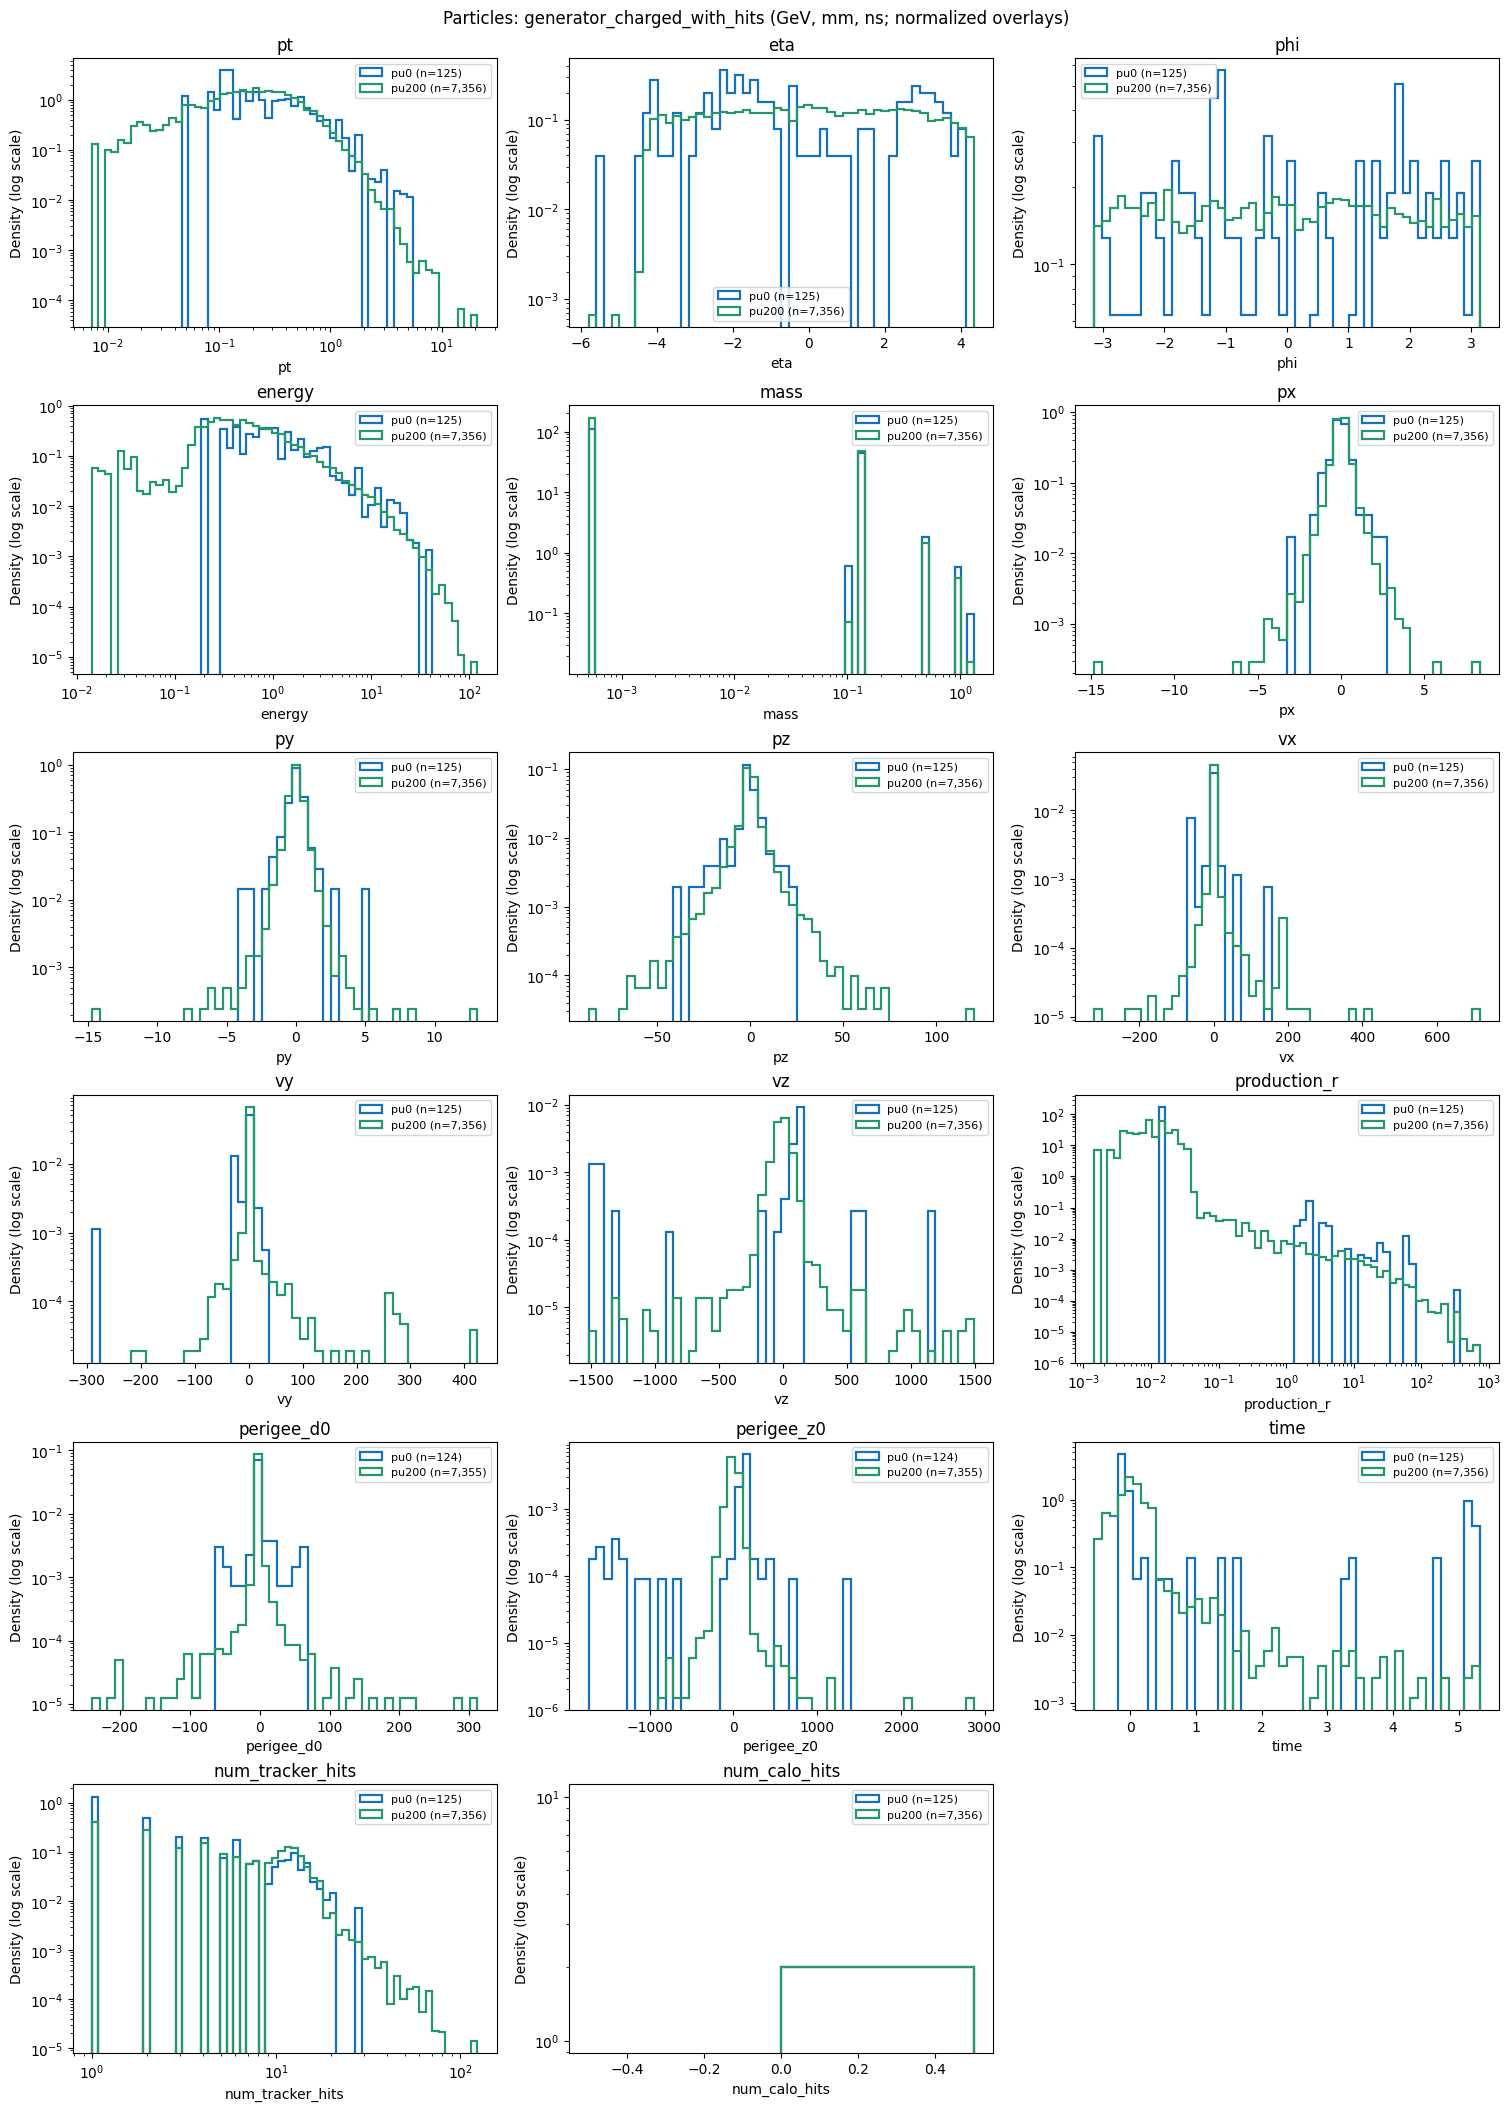

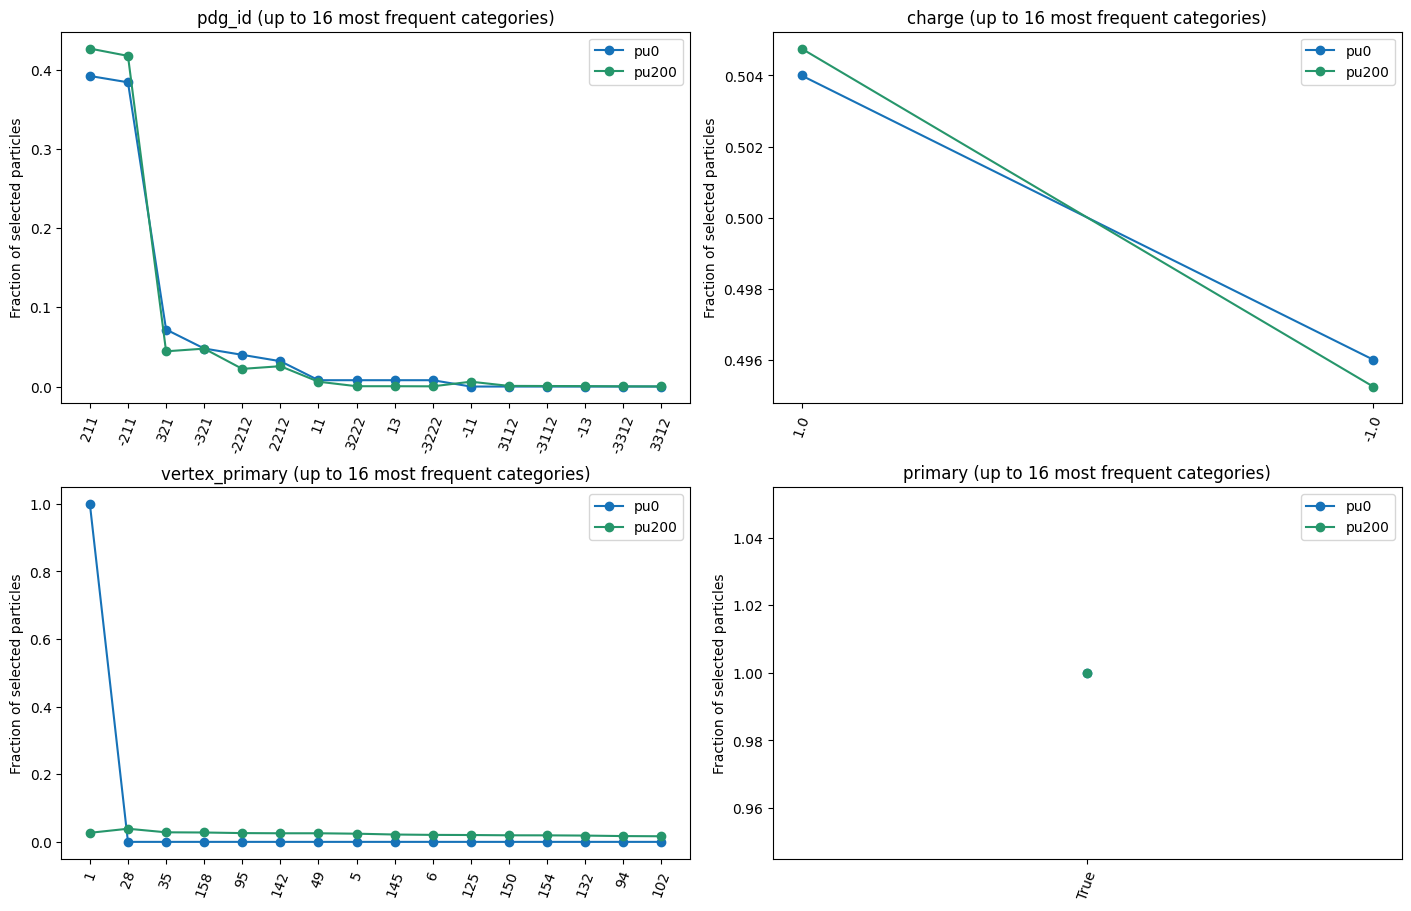

,particle_id,pdg_id,mass,pt,px,py,pz,vx,vy,vz,production_r,sample
0,614,36,55.0,13.383663,11.055432,-7.543200,-190.254196,-0.003953,0.014816,121.691368,0.015335,pu0
1,615,36,55.0,19.361446,-17.650900,-7.956844,-479.348297,-0.003953,0.014816,121.691368,0.015335,pu0
2,1234,36,55.0,109.903694,62.587074,90.342018,-21.129513,0.013980,-0.033074,-76.720757,0.035908,pu200
3,1235,36,55.0,48.693913,45.008900,18.582142,4.331967,0.013980,-0.033074,-76.720757,0.035908,pu200


,sample,llps,charged_with_hits,displaced_charged_with_hits
0,pu0,2,619,530
1,pu200,2,39396,32444


In [5]:
validation.plot_particles(samples, PARTICLE_COHORT)
llps = pd.concat([
    sample.particles.loc[sample.particles.pdg_id.abs() == 36,
        ["particle_id", "pdg_id", "mass", "pt", "px", "py", "pz", "vx", "vy", "vz", "production_r"]].assign(sample=name)
    for name, sample in samples.items()
], ignore_index=True)
display(llps)
display(pd.DataFrame([
    dict(sample=name, llps=int((sample.particles.pdg_id.abs() == 36).sum()),
         charged_with_hits=len(validation.particle_selection(sample.particles)),
         displaced_charged_with_hits=len(validation.particle_selection(sample.particles, "displaced_charged_with_hits")))
    for name, sample in samples.items()
]))

## Detector coverage and hit features

Production vertices and measurement positions use separate panels. Dense spatial views use deterministic sampling only; integrity counts and histograms use the complete selected events. Both pileup settings appear on the same axes. Hit `local0/local1` are signed sensor-local coordinates, not channel addresses.

No hit positions have been recomputed using quantized cell codes.

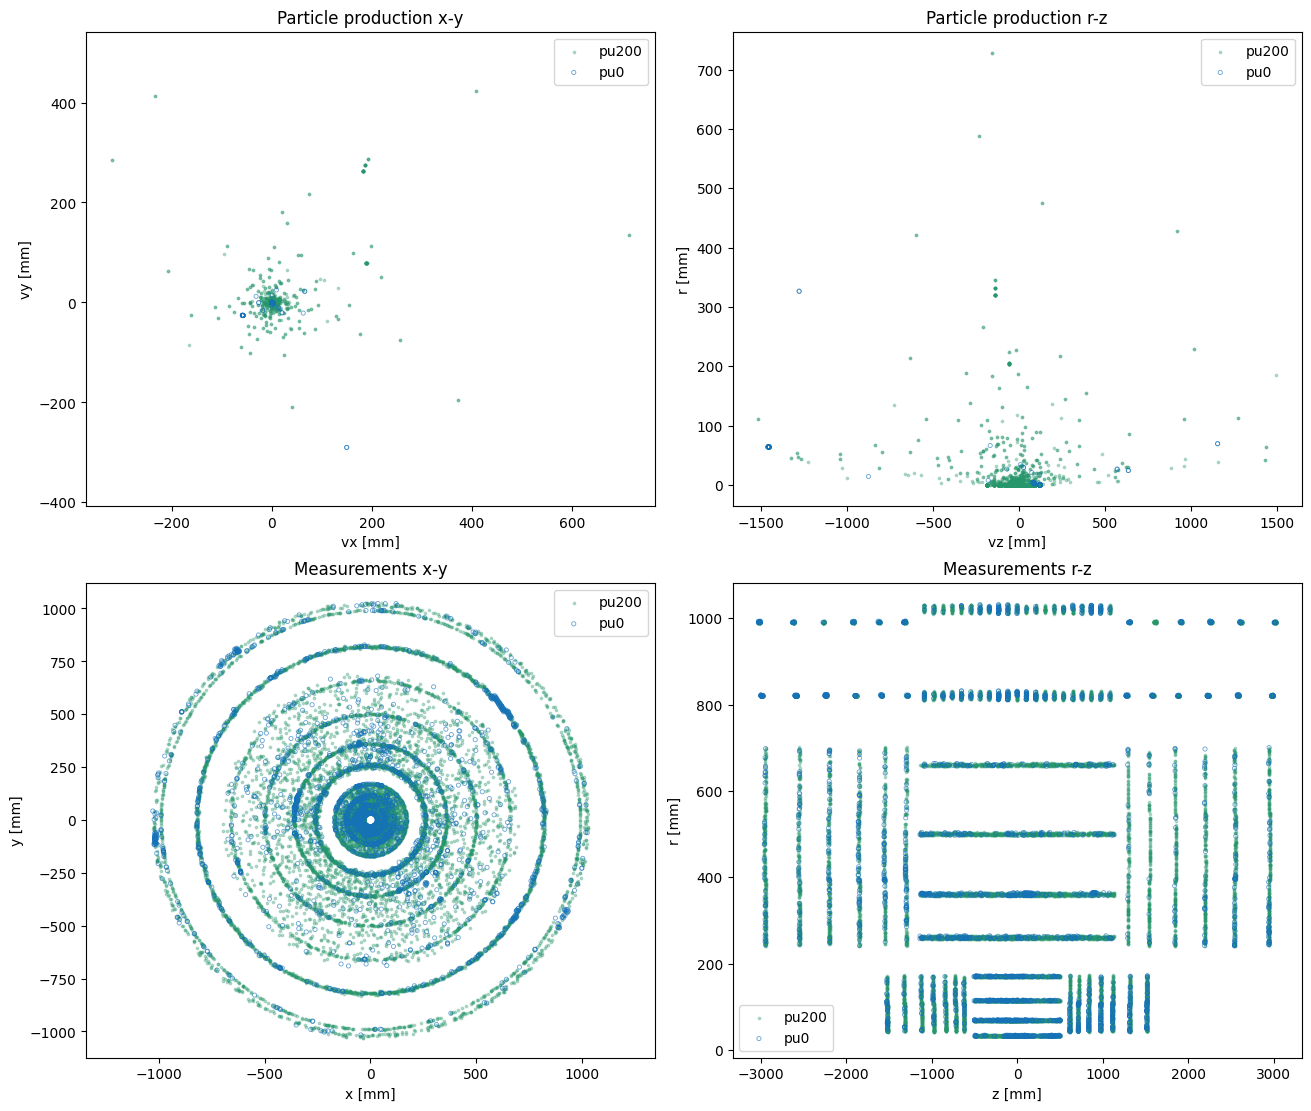

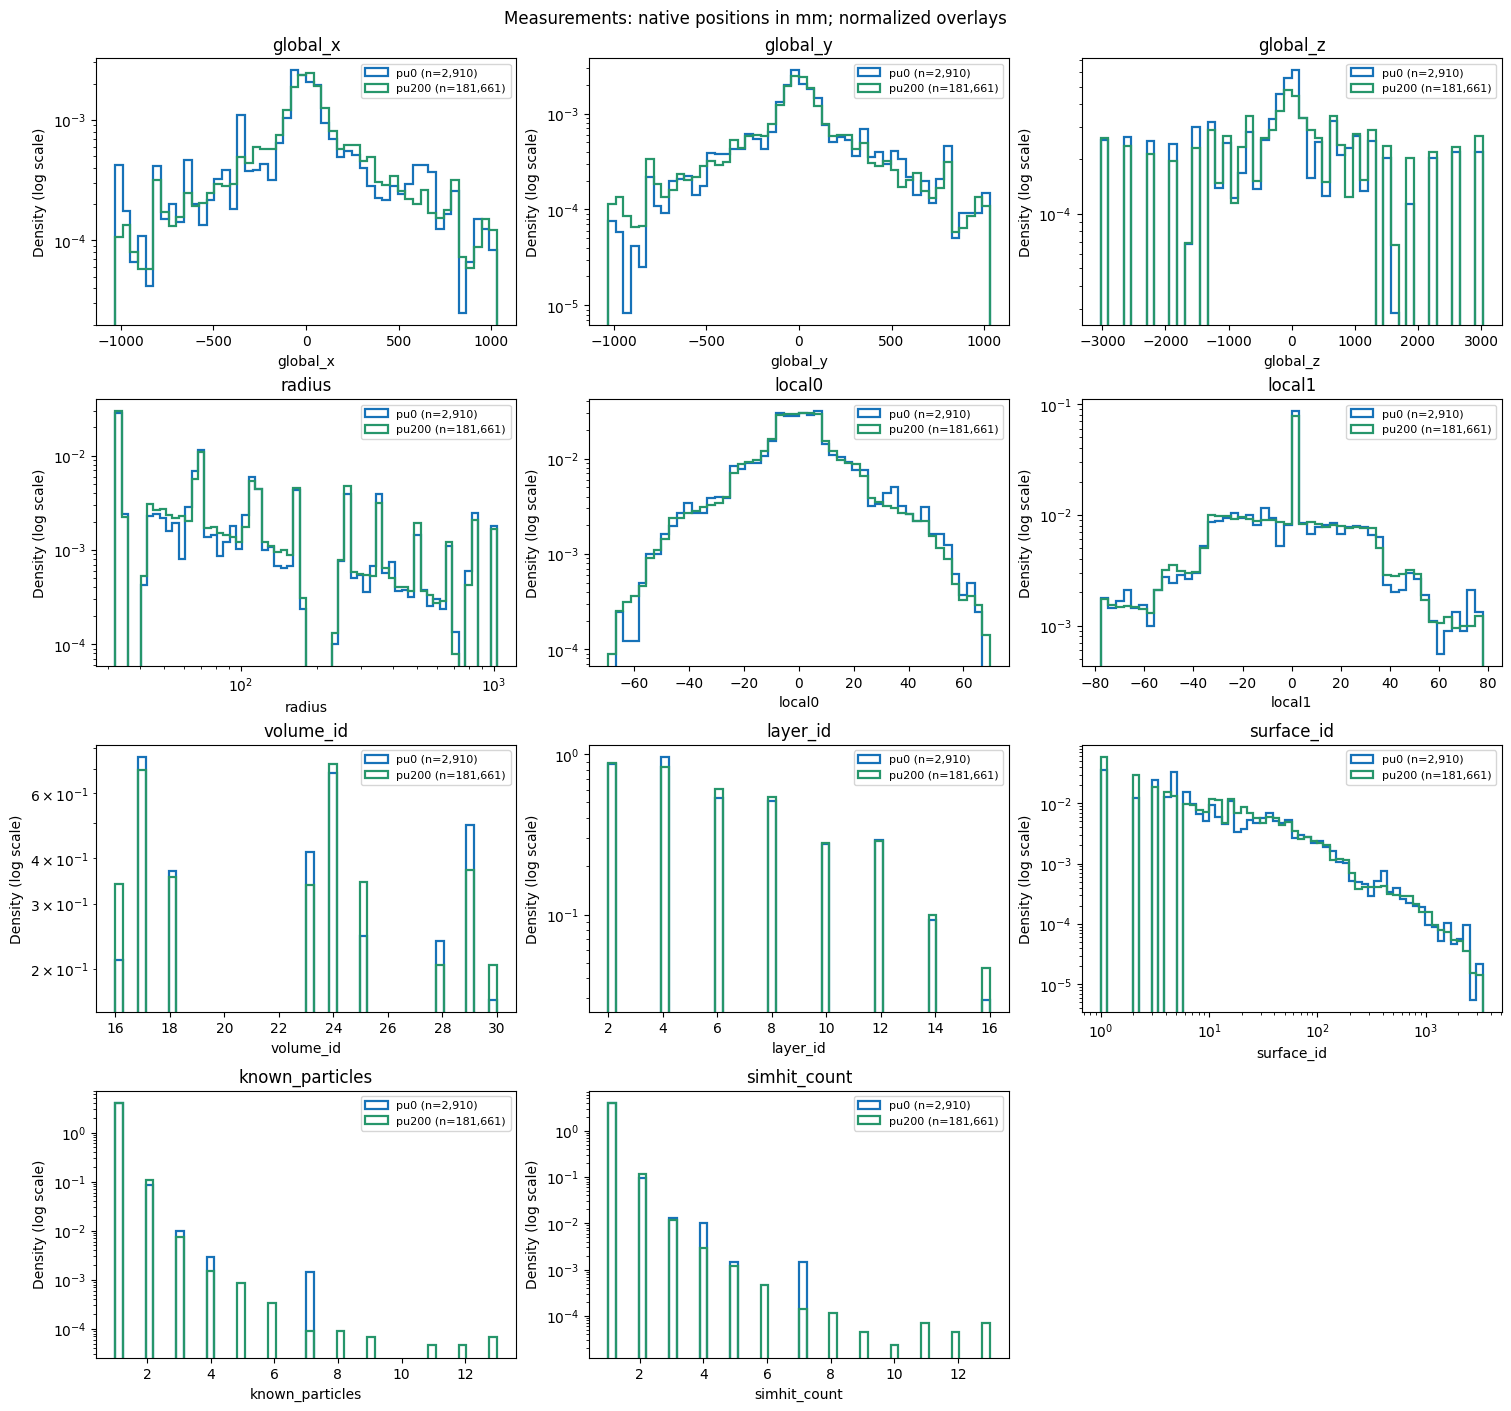

In [6]:
validation.plot_spatial(samples, SCATTER_LIMIT, SEED, PARTICLE_COHORT)
validation.plot_hits(samples)

## Cells, cluster sizes and contributors

Activation remains the native ACTS path-length proxy in mm, after its configured noise/threshold/merging. A large activation does not by itself imply several particles. Particle multiplicity below belongs to the **parent cluster**, not to an individual cell. Incomplete truth is a separate category.

Cell and cluster denominators are reported separately. Full-range survival curves and largest-cell tables retain rare extremes.

,sample,local_event,detector_type,clusters,cells,incomplete_clusters,maximum_activation,max_cell_parent_particles,max_cell_parent_simhits,max_cell_truth_complete,cell_tail_fraction,cluster_tail_fraction,complete_truth_tail_cells,multi_particle_parent_fraction_of_complete_tail
0,pu0,0,Long strips,728,4016,0,7.088085,1,1,True,0.010956,0.027473,44,0.454545
1,pu0,0,Pixels,1088,6590,0,0.688644,7,7,True,0.000152,0.000919,1,1.000000
2,pu0,0,Short strips,1094,4520,0,0.634113,2,2,True,0.003319,0.010969,15,0.333333
3,pu200,0,Long strips,39643,193799,0,10.812551,1,1,True,0.023029,0.045203,4463,0.504369
4,pu200,0,Pixels,70633,375521,0,1.211983,7,7,True,0.000027,0.000127,10,1.000000
5,pu200,0,Short strips,71385,286430,1,2.108026,6,6,True,0.005411,0.012650,1548,0.299096


,sample,local_event,detector_type,truth_complete,known_particles,cells,activation_median,activation_q95,activation_q995,activation_max,tail_cells,cell_tail_fraction,clusters,tail_clusters,cluster_tail_fraction,diagnostic_threshold
0,pu0,0,Long strips,True,1,2854,0.151583,0.297031,0.635146,7.088085,24,0.008409,705,14,0.019858,0.5
1,pu0,0,Long strips,True,2,1132,0.110075,0.297670,0.561125,4.195377,18,0.015901,22,5,0.227273,0.5
2,pu0,0,Long strips,True,3,30,0.238011,0.474791,0.994777,1.068213,2,0.066667,1,1,1.000000,0.5
3,pu0,0,Pixels,True,1,5541,0.049445,0.117252,0.139092,0.180287,0,0.000000,1072,0,0.000000,0.5
4,pu0,0,Pixels,True,2,569,0.047770,0.072635,0.148866,0.186218,0,0.000000,10,0,0.000000,0.5
5,pu0,0,Pixels,True,3,194,0.044086,0.089761,0.130093,0.160661,0,0.000000,3,0,0.000000,0.5
6,pu0,0,Pixels,True,4,42,0.048422,0.188153,0.397138,0.450228,0,0.000000,2,0,0.000000,0.5
7,pu0,0,Pixels,True,7,244,0.047158,0.076486,0.370901,0.688644,1,0.004098,1,1,1.000000,0.5
8,pu0,0,Short strips,True,1,3900,0.102169,0.238050,0.457436,0.540561,10,0.002564,1062,7,0.006591,0.5
9,pu0,0,Short strips,True,2,554,0.099788,0.250826,0.507970,0.634113,4,0.007220,29,4,0.137931,0.5


,sample,campaign,dataset,version,run,local_event,measurement_id,detector_type,volume_id,channel0,channel1,value,n_cells,activation_sum,known_particles,simhit_count,truth_complete
0,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2604,Long strips,29,79,0,7.088085,2,7.528901,1,1,True
1,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2689,Long strips,29,252,0,4.195377,4,8.136470,2,2,True
2,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2689,Long strips,29,253,0,3.592250,4,8.136470,2,2,True
3,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2711,Long strips,29,504,0,3.260959,10,5.519304,2,4,True
4,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2800,Long strips,30,518,0,1.947662,1,1.947662,1,1,True
5,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2366,Long strips,28,76,0,1.890563,2,3.242562,1,1,True
6,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2366,Long strips,28,77,0,1.351998,2,3.242562,1,1,True
7,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2606,Long strips,29,476,0,1.068213,30,7.739457,3,3,True
8,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2711,Long strips,29,500,0,1.060021,10,5.519304,2,4,True
9,pu0,hard_scatter,higgs_portal,v2_cells_pilot,3,0,2903,Long strips,30,558,0,0.921372,2,1.556643,1,1,True


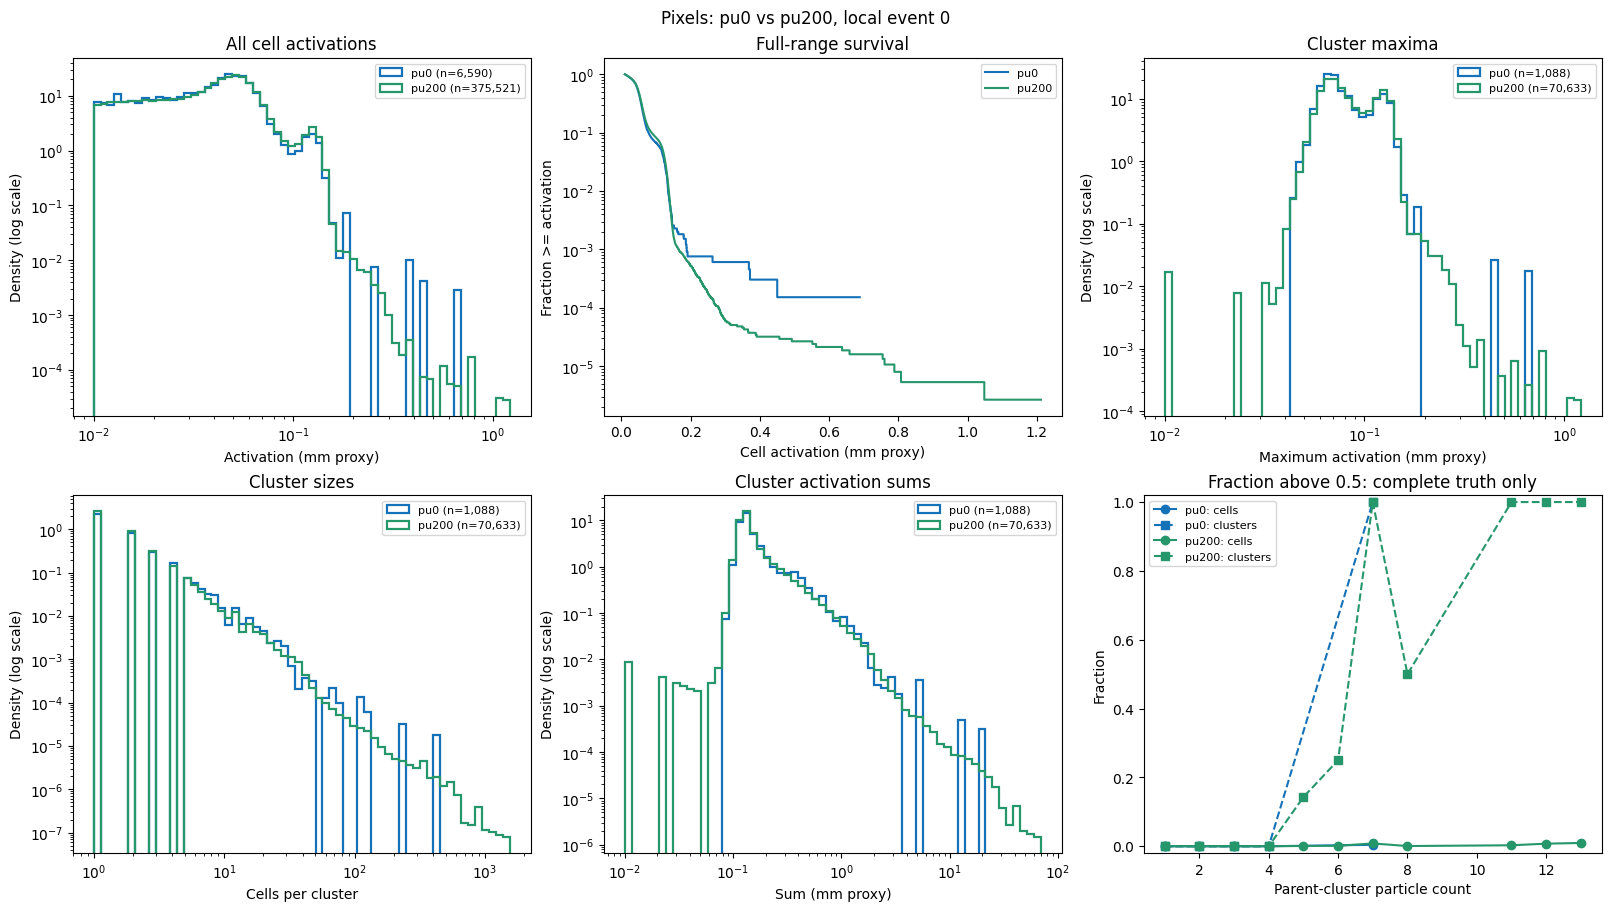

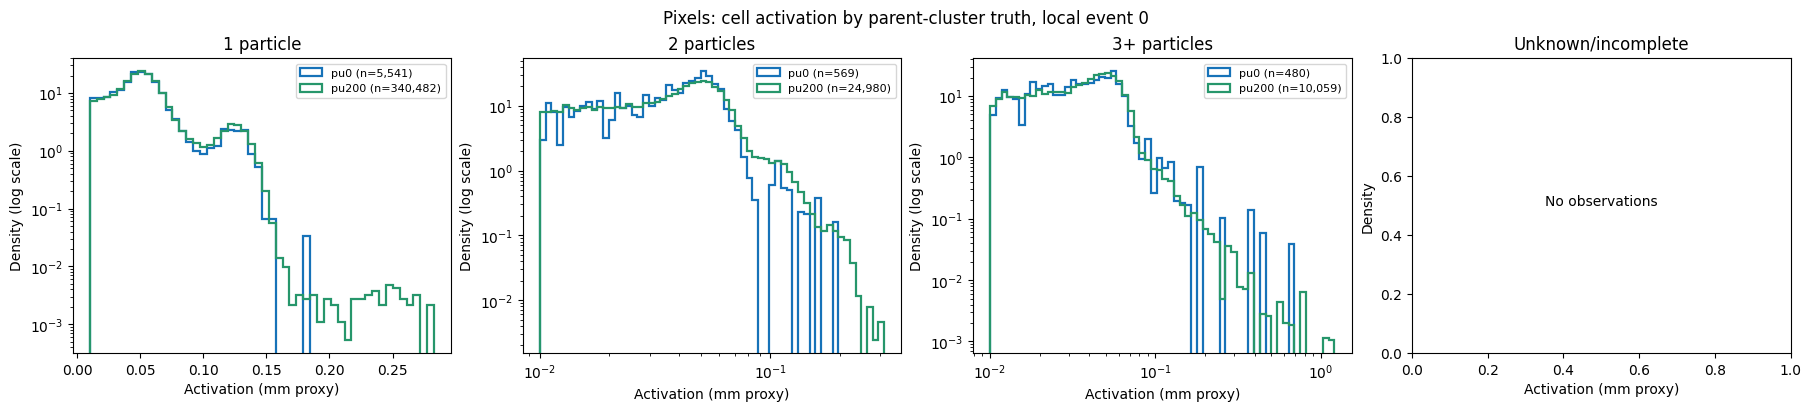

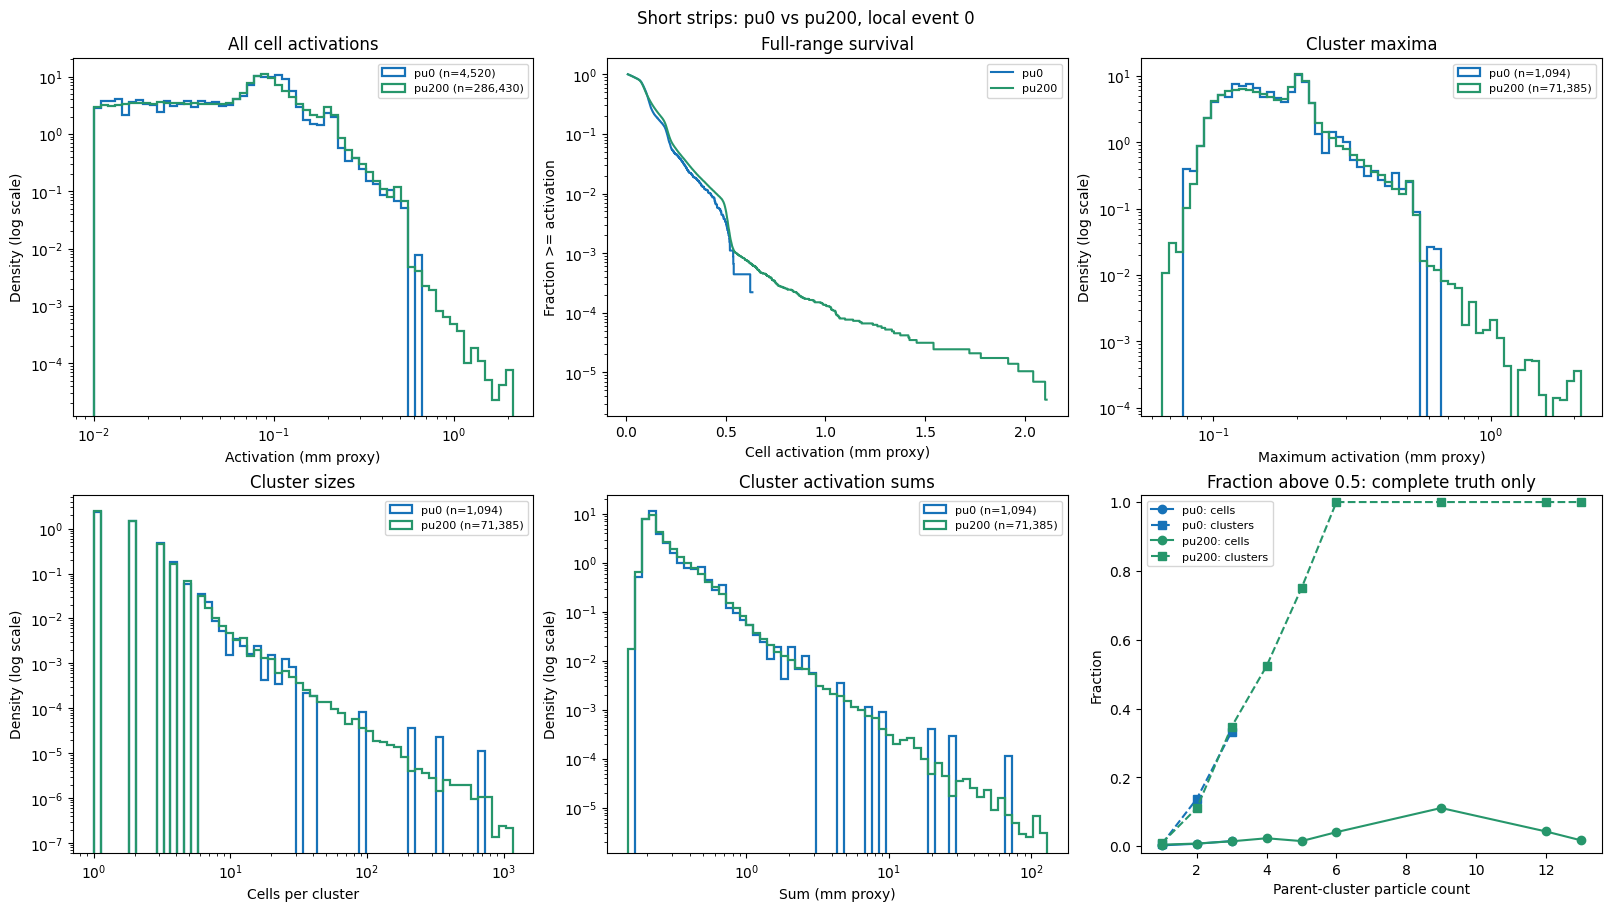

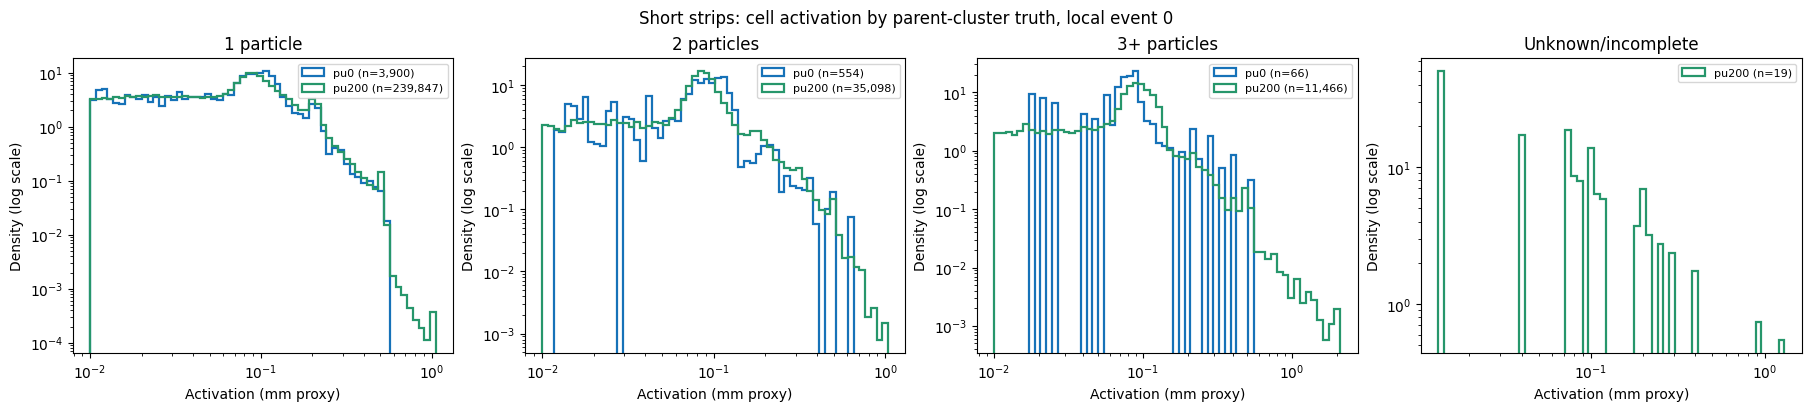

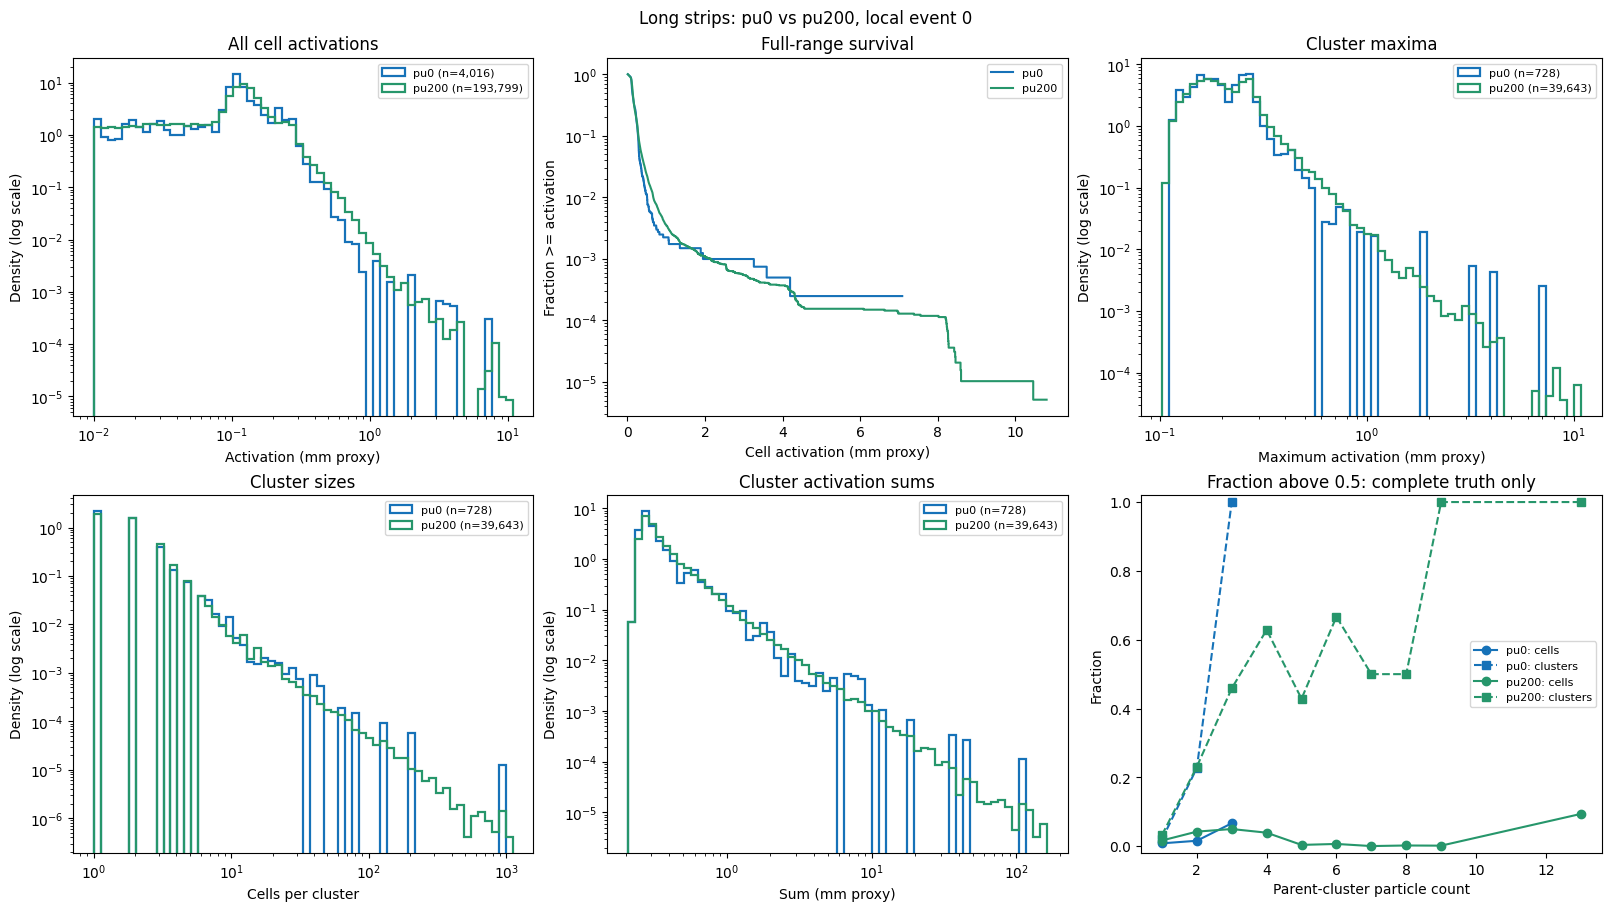

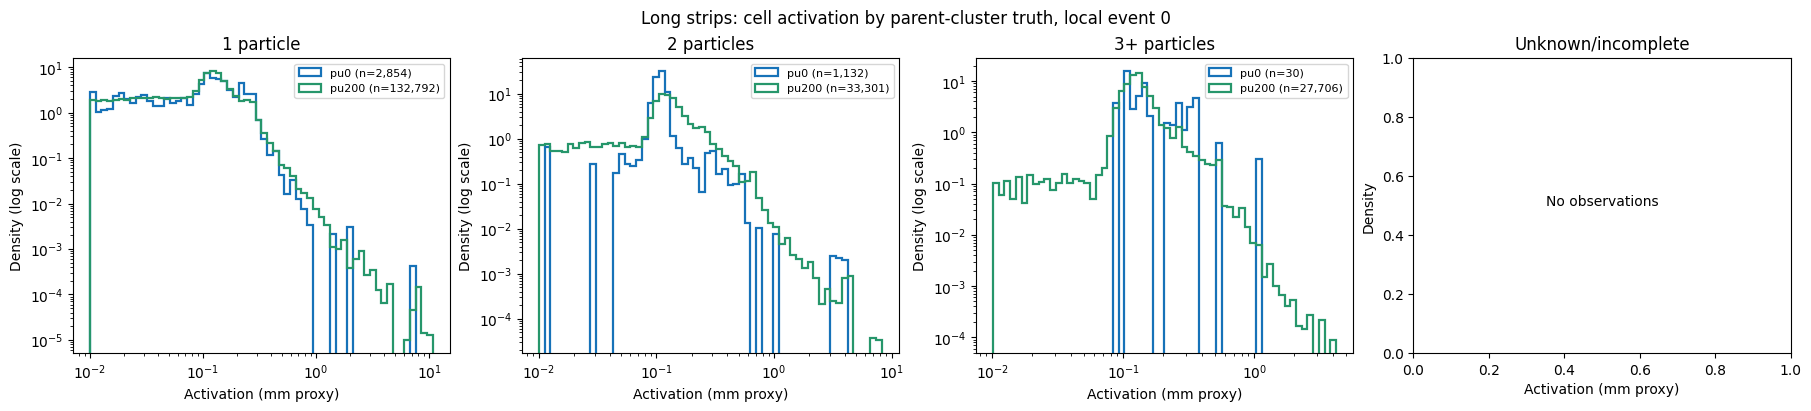

In [7]:
display(paired.pileup_event_summary(analyses))
display(paired.contributor_statistics(analyses))
display(paired.largest_cells(analyses, per_sample=10))
paired.plot_pileup_comparison(analyses)

## Frozen P99.9 pixel-code validation

The mapping was calibrated on ttbar pu200, not refitted to Higgs portal. Recompute every selected pixel code from the stored boundaries with upper-bin ties. Require positive codes 1-15 on pixels and null codes on strips.

Code 15 includes its nominal bin and true overflow. The table distinguishes all code-15 cells from values beyond the nominal code-15 bin end. This validates storage and frozen-map application, not electronics realism or a calibrated ATLAS response.

,scheme,pixel_cells,code15_cells,code15_fraction,genuinely_clipped_cells,clipped_fraction,native_max,checks
sample,,,,,,,,
pu0,p99.9,6590,12,0.001821,12,0.001821,0.688644,PASS
pu200,p99.9,375521,377,0.001004,314,0.000836,1.211983,PASS


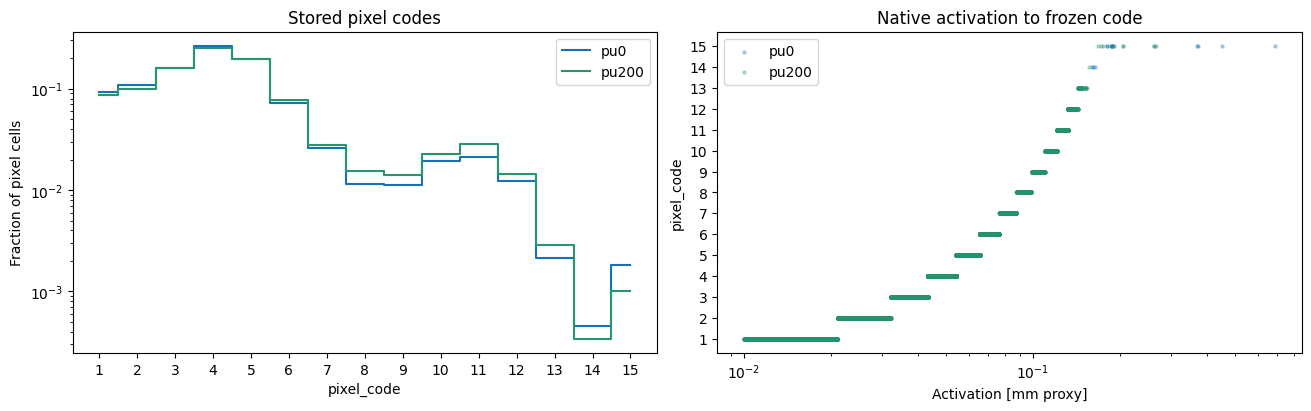

In [8]:
display(validation.quantization(samples))
validation.plot_codes(samples)

## Example cluster images

Six different available cluster sizes per detector type, nearest to the configured targets, selected deterministically. Each gallery has a shared native-activation color scale. Images show actual channel addresses with one channel of padding; square drawn pixels do not imply square physical cells. There is no image-window cropping. Change `GALLERY_SAMPLE` to inspect the other sample.

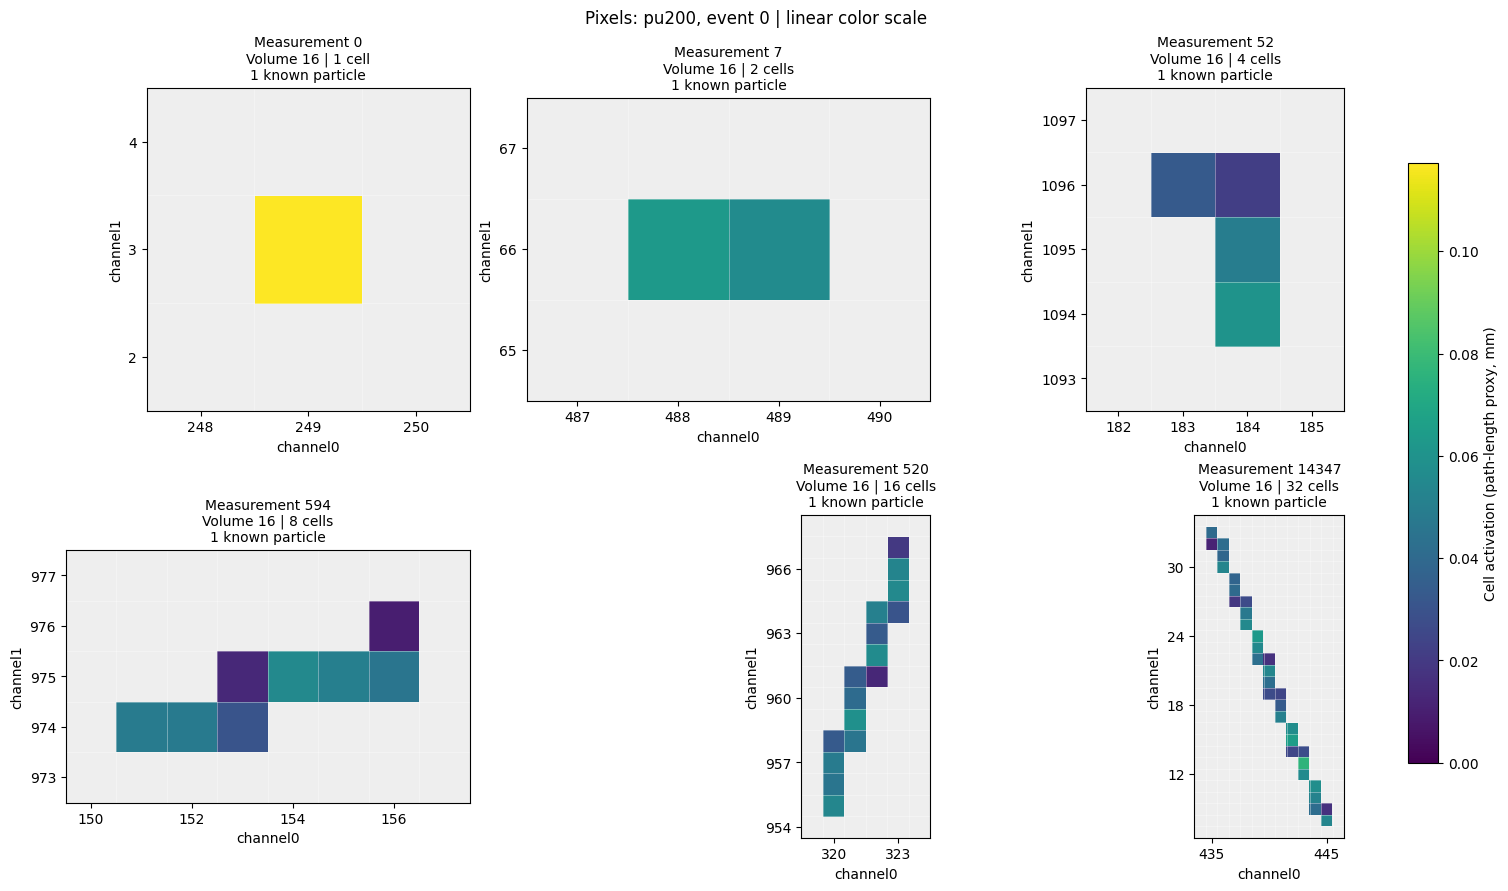

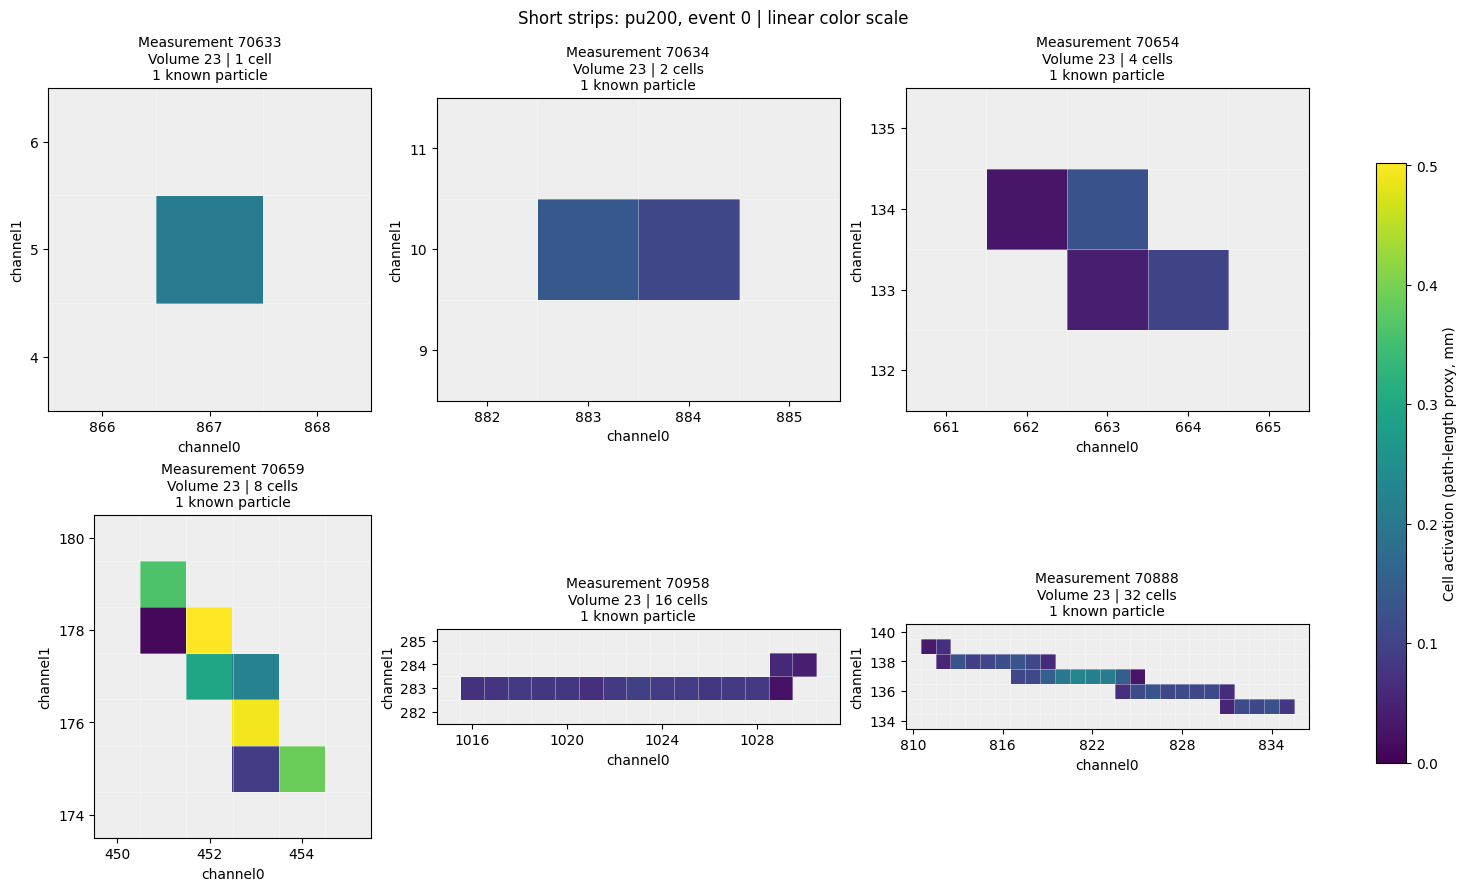

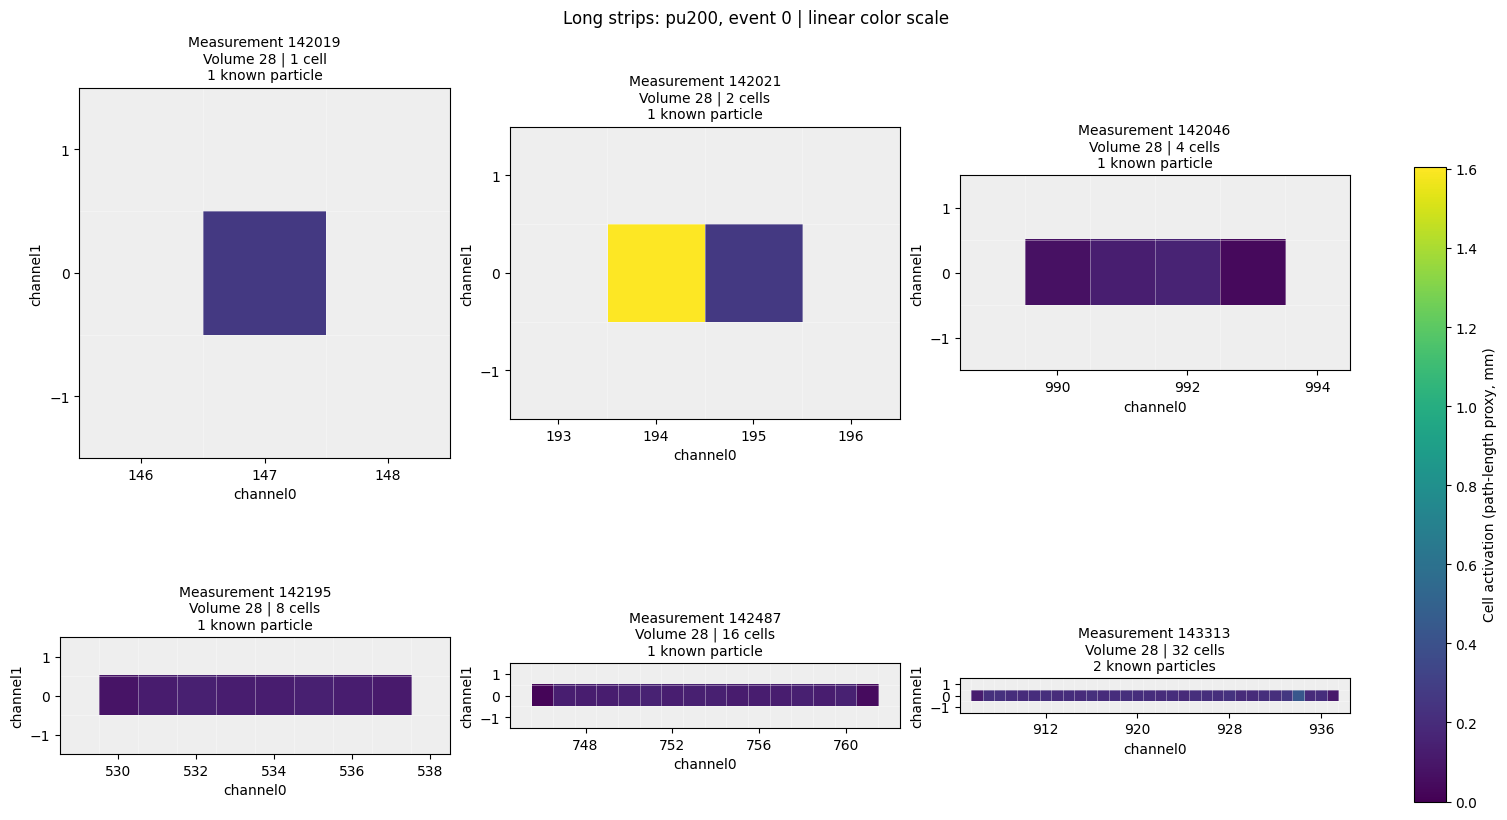

,Detector type,Target cells,Measurement ID,Volume,Cells,Known particles,Truth complete,Value sum,Minimum value,Maximum value
0,Pixels,1,0,16,1,1,True,0.117268,0.117268,0.117268
1,Pixels,2,7,16,2,1,True,0.119648,0.056480,0.063168
2,Pixels,4,52,16,4,1,True,0.164972,0.021578,0.060305
3,Pixels,8,594,16,8,1,True,0.302381,0.010060,0.055126
4,Pixels,16,520,16,16,1,True,0.673996,0.013210,0.059023
5,Pixels,32,14347,16,32,1,True,1.353738,0.011641,0.076077
6,Short strips,1,70633,23,1,1,True,0.206592,0.206592,0.206592
7,Short strips,2,70634,23,2,1,True,0.245310,0.106296,0.139014
8,Short strips,4,70654,23,4,1,True,0.302223,0.030370,0.125846
9,Short strips,8,70659,23,8,1,True,2.368851,0.011074,0.502065


In [9]:
display(validation.cluster_gallery(samples[GALLERY_SAMPLE], CLUSTER_TARGET_SIZES))

## Several independent event displays

Inspect configured local events in both pileup settings. The second figure for each event shows measurements linked through `particle_ids` to displaced generator-origin charged particles with tracker hits. These are truth-linked measurements, **not reconstructed tracks** and not a signal-only selection; pileup generator particles can qualify. Unknown contributors are not invented.

Coordinates on particle plots are production vertices. Actual LLP decay endpoints are checked in the saved Geant4 validation report, not stored in the particle Parquet schema. Deterministic sampling affects spatial rendering only.

Spatial preview: local event 0 in each independent sample


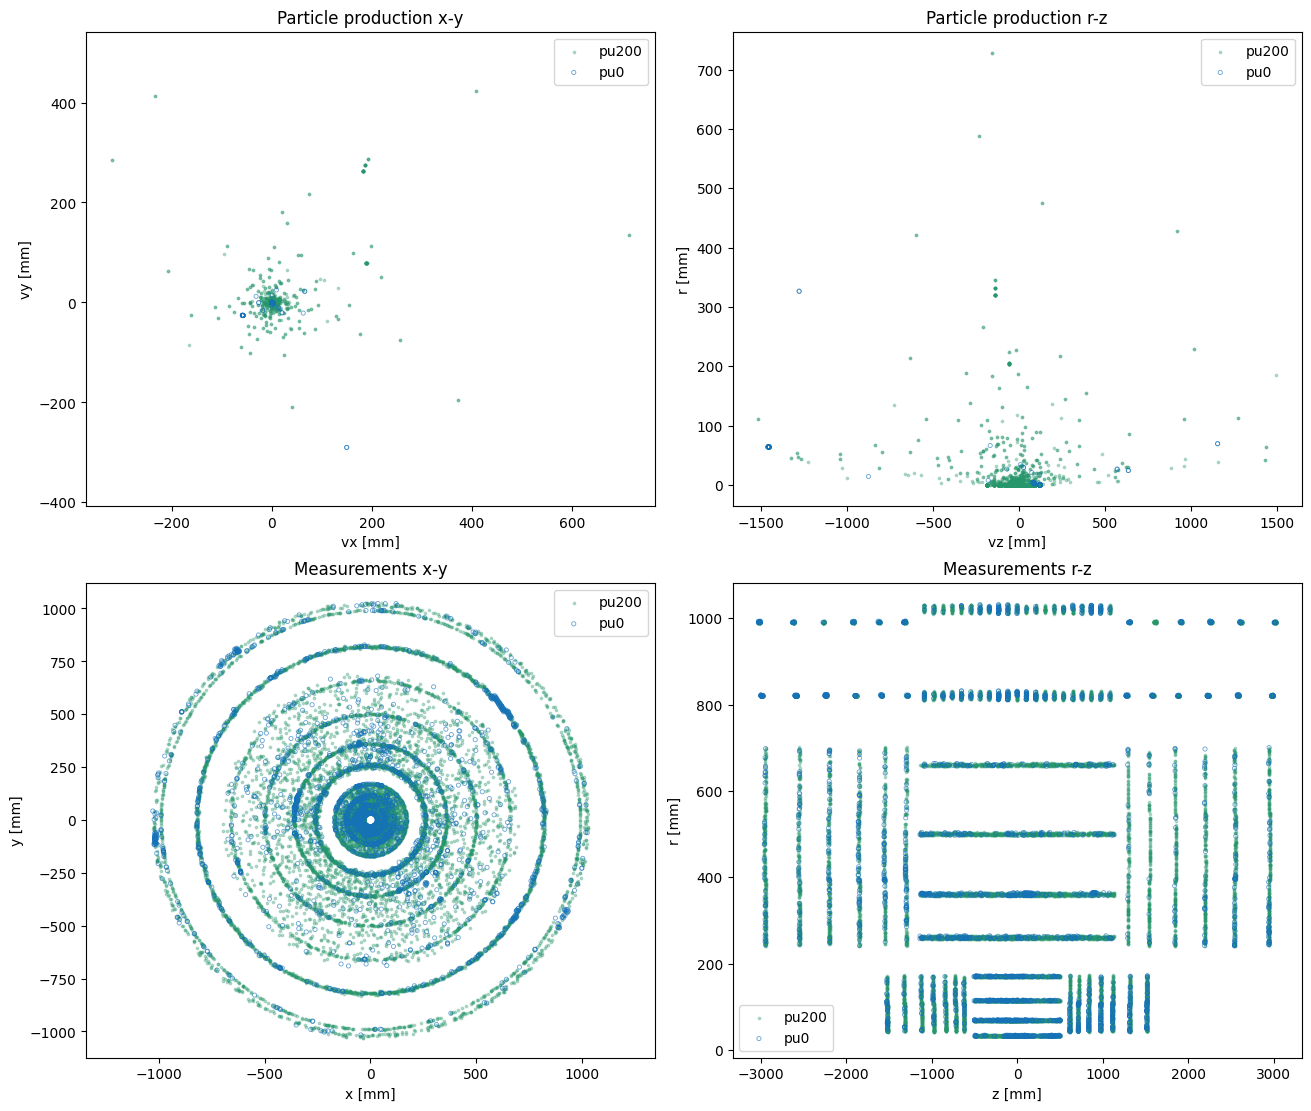

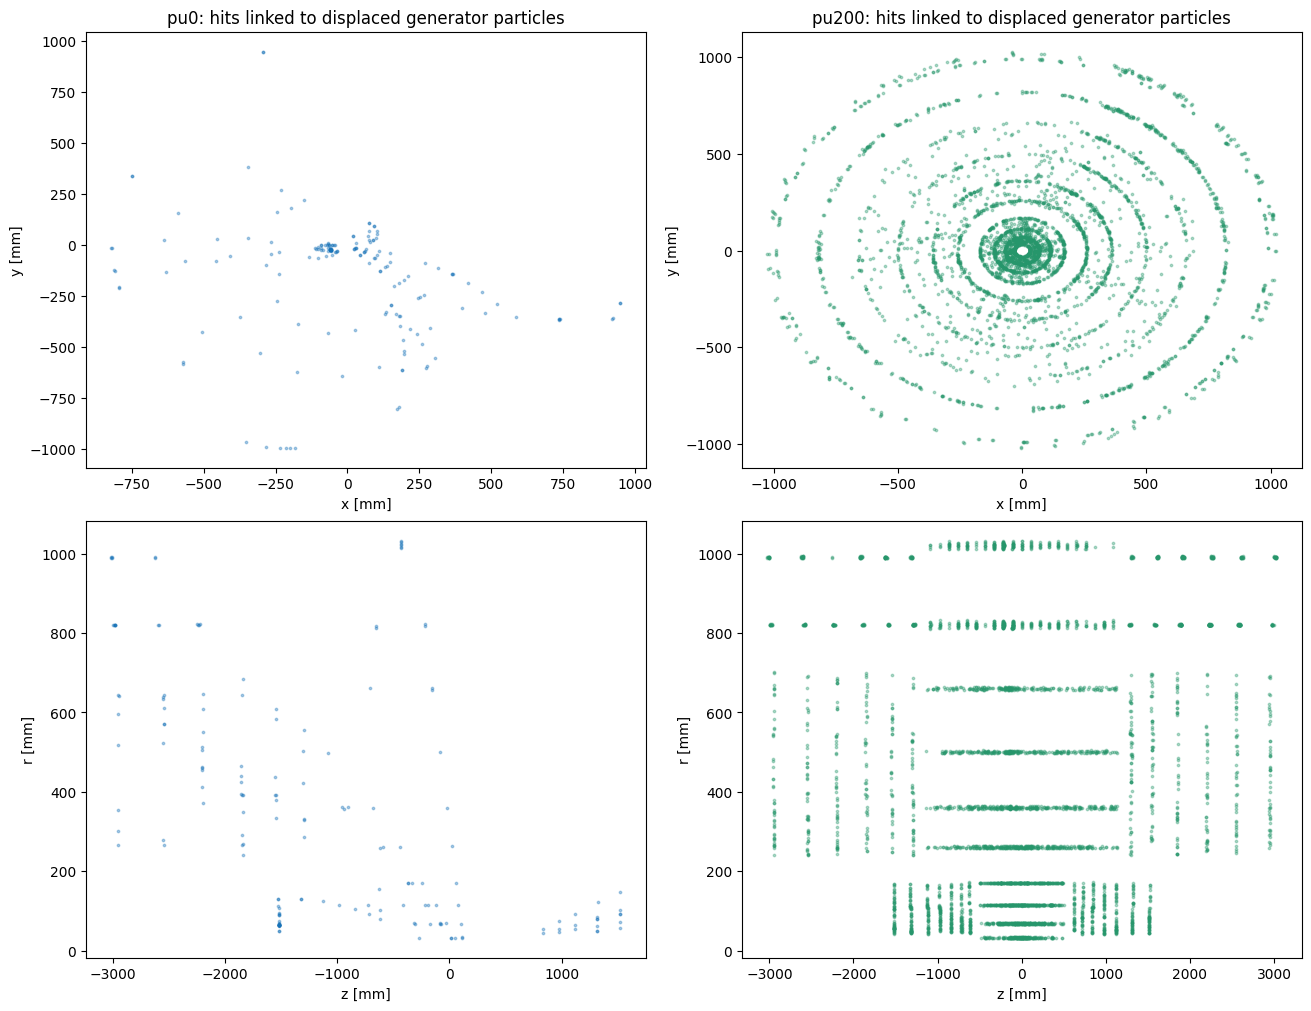

Spatial preview: local event 24 in each independent sample


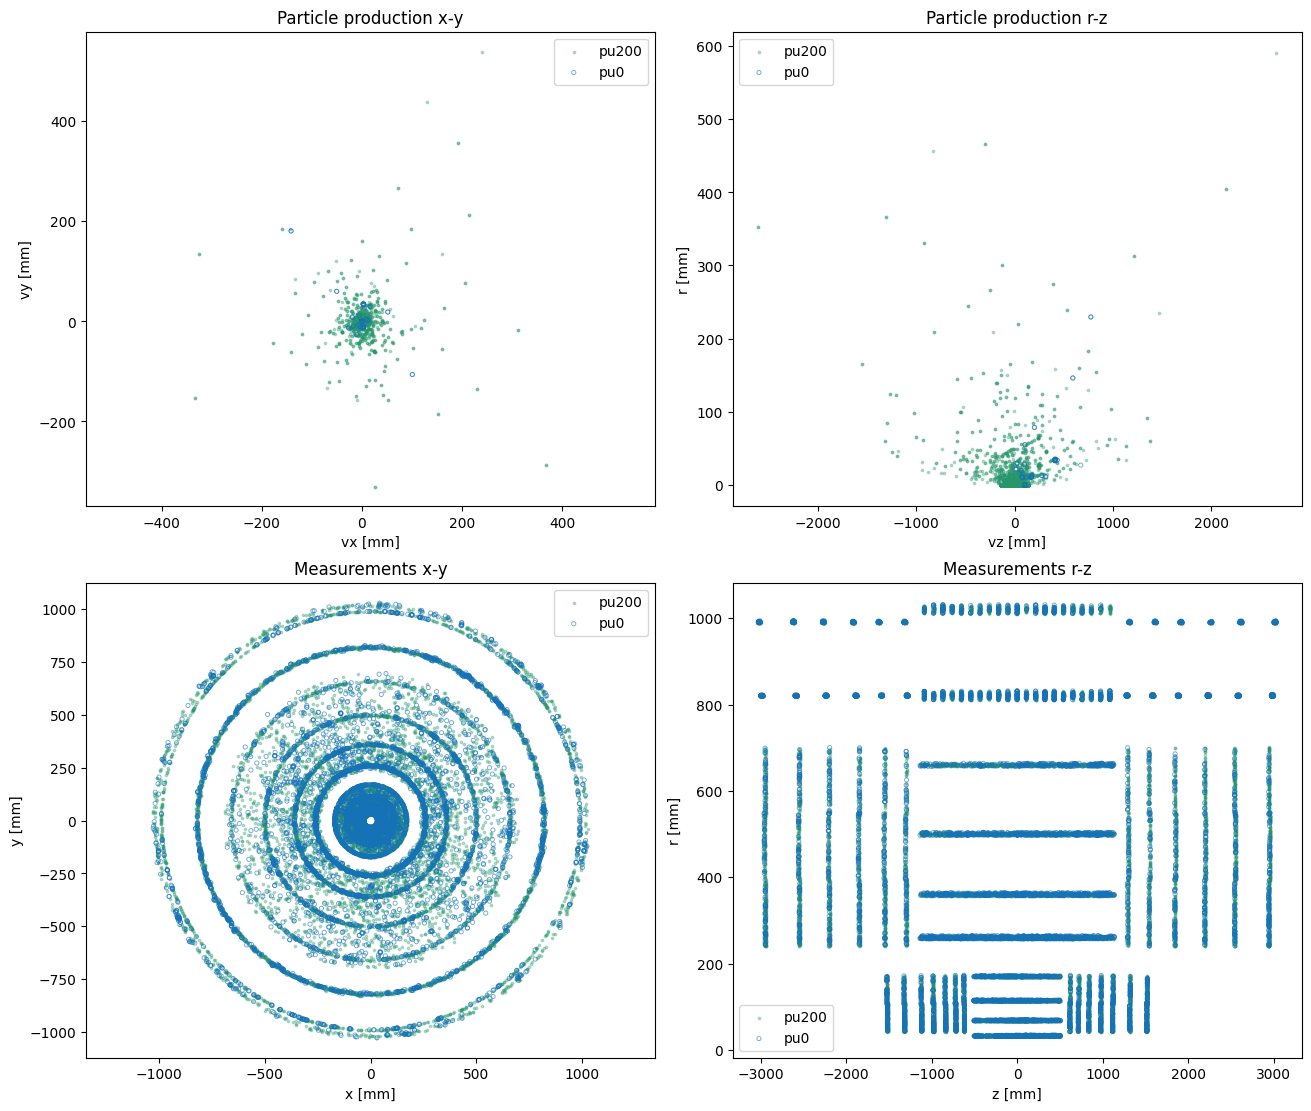

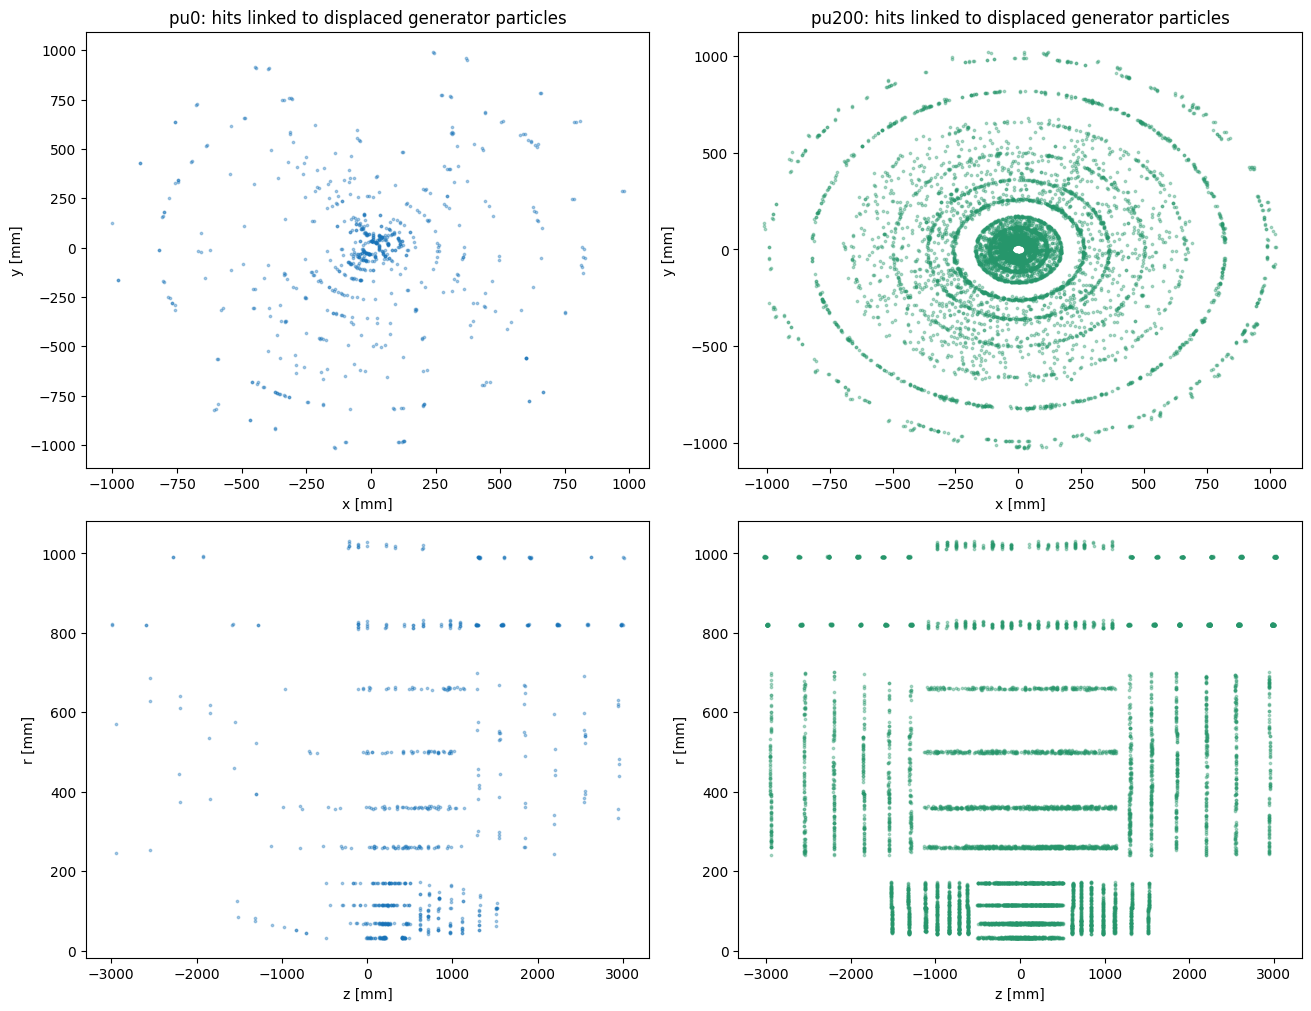

Spatial preview: local event 99 in each independent sample


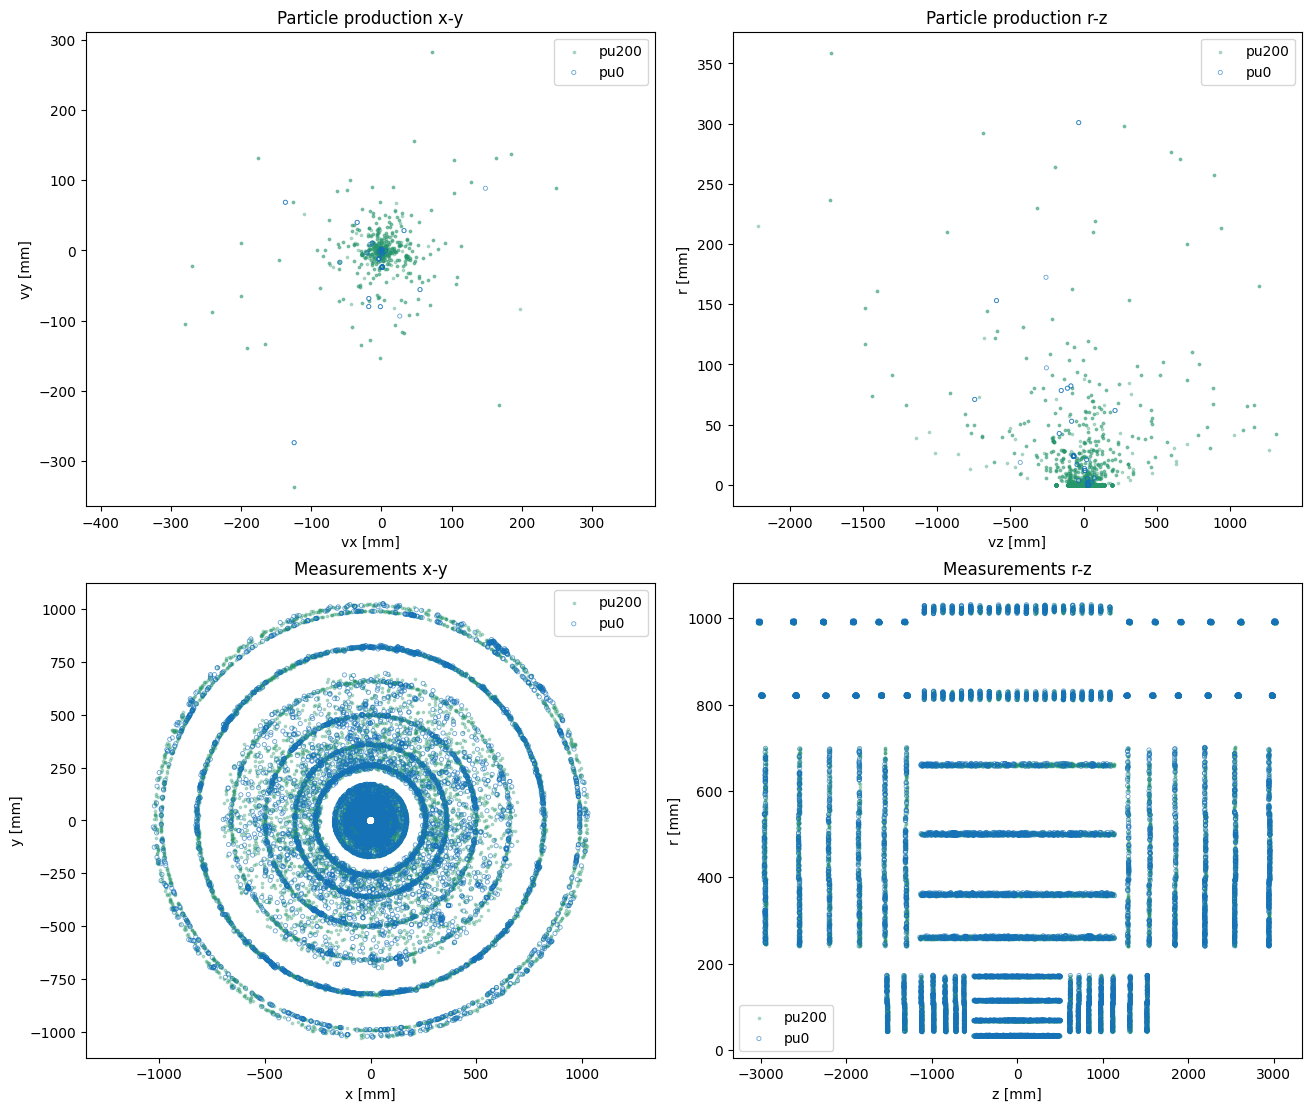

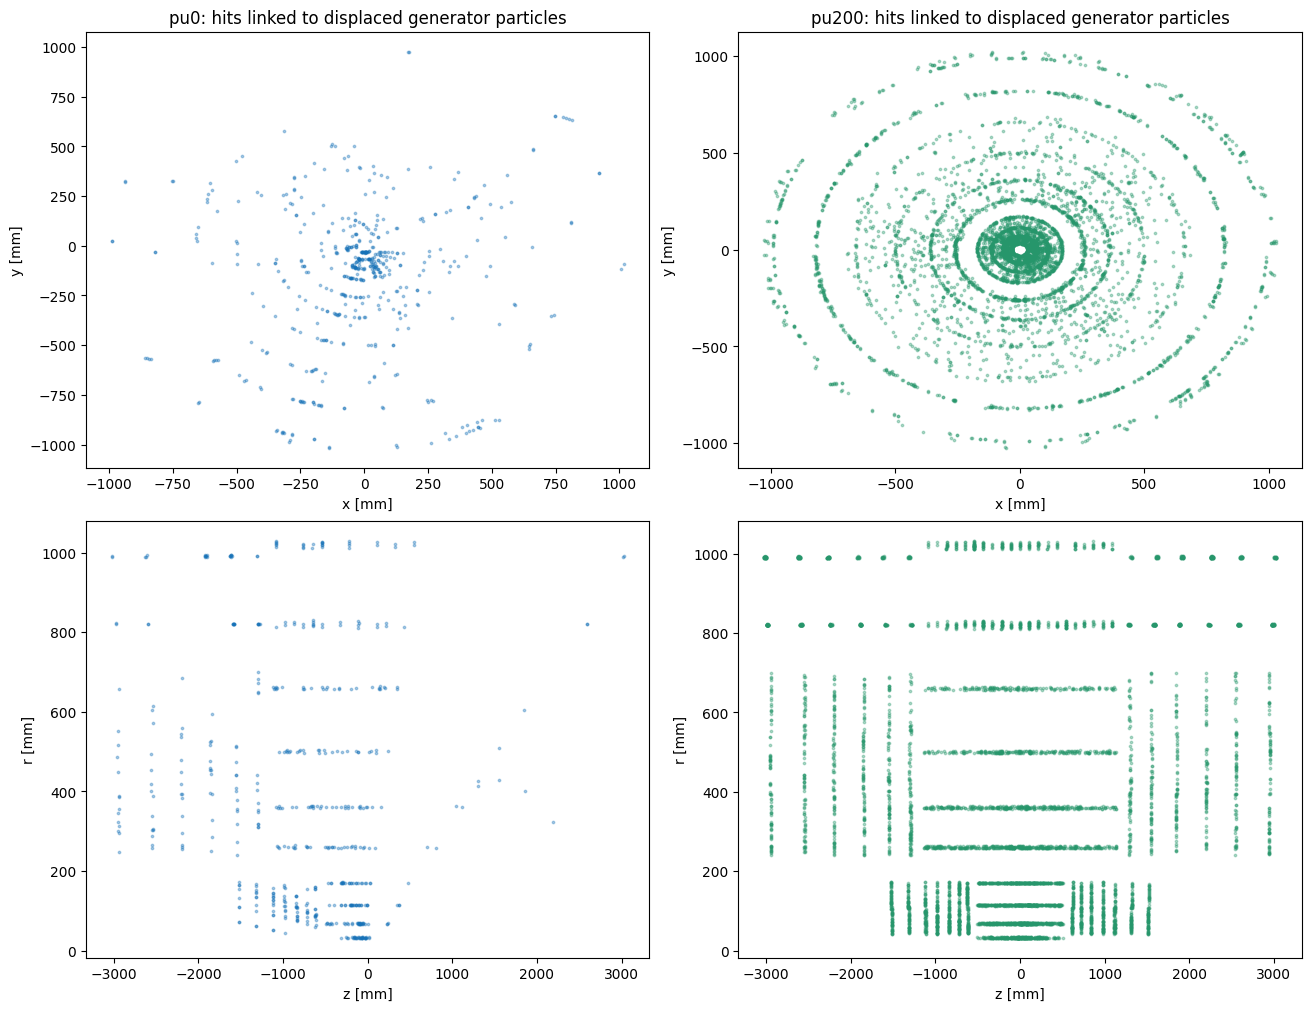

In [10]:
available_events = set(range(complete["events_per_sample"]))
for preview_event in PREVIEW_EVENTS:
    if preview_event not in available_events:
        print("Skipping unavailable preview event", preview_event)
        continue
    print("Spatial preview: local event", preview_event, "in each independent sample")
    preview = validation.load_samples(PAIRED_ROOT, preview_event, include_cells=False)
    validation.plot_spatial(preview, SCATTER_LIMIT, SEED, PARTICLE_COHORT)
    validation.plot_linked_hits(preview, SCATTER_LIMIT, SEED)
    del preview

## All-event integrity, truth flags and quantization

This is a full scan, not a sample: each hits/cells shard is read once in increasing event order, alongside one nested particle row at a time. It checks full-key cell-to-hit joins, unique channel addresses, geometry, existing particle labels/contributors, event sets, frozen pixel encoding and null strip codes. Totals must reproduce `report.json`, including all unresolved links and legacy-label disagreements. Memory use is bounded by a single event plus input batches; source Parquets stay unchanged.

Truth limitations are distinct: an **incomplete list** is a lower bound because some SimHits could not be resolved uniquely; a **legacy-label disagreement** is a different result from production's coordinate matcher for a complete contributor list. It is not another unresolved SimHit. Use `particle_ids`, `particle_ids_complete` and `unresolved_simhit_ids` together. The table lists every flagged hit in the full scan, with lists retained. No flags are suppressed or automatically repaired.

Finite-perigee coverage is shown by cohort and event. A finite value is not an independent proof of numerical correctness; this does not replace the original numerical-reference study.

pu0: checked 10/100 complete events
pu0: checked 20/100 complete events
pu0: checked 30/100 complete events
pu0: checked 40/100 complete events
pu0: checked 50/100 complete events
pu0: checked 60/100 complete events
pu0: checked 70/100 complete events
pu0: checked 80/100 complete events
pu0: checked 90/100 complete events
pu0: checked 100/100 complete events
pu200: checked 10/100 complete events
pu200: checked 20/100 complete events
pu200: checked 30/100 complete events
pu200: checked 40/100 complete events
pu200: checked 50/100 complete events
pu200: checked 60/100 complete events
pu200: checked 70/100 complete events
pu200: checked 80/100 complete events
pu200: checked 90/100 complete events
pu200: checked 100/100 complete events


,measurements,cells,particles,llps,orphan_cells,hits_without_cells,missing_parent_ids,unresolved_simhit_links,incomplete_truth_measurements,converted_label_disagreements
sample,,,,,,,,,,
pu0,491444,2436079,504732,200,0,0,0,3,2,0
pu200,22966008,109687252,27779207,200,0,0,0,70,53,47


,sample,event,measurements,cells,particles,simhit_links,null_particle_labels,multi_particle_measurements,unresolved_simhit_links,incomplete_truth_measurements,converted_label_disagreements,orphan_cells,hits_without_cells,missing_parent_ids,association_checks,llps
0,pu0,0,2910,15126,2908,3026,71,71,0,0,0,0,0,0,PASS,2
1,pu0,1,1844,9147,2671,1901,42,42,0,0,0,0,0,0,PASS,2
2,pu0,2,2685,14177,3217,2768,54,54,1,1,0,0,0,0,PASS,2
3,pu0,3,3171,17169,3380,3308,94,94,0,0,0,0,0,0,PASS,2
4,pu0,4,2125,9642,2820,2194,51,51,0,0,0,0,0,0,PASS,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,pu200,95,273936,1335999,333278,285723,8468,8468,3,3,0,0,0,0,PASS,2
196,pu200,96,203870,975383,249026,211843,5789,5789,0,0,0,0,0,0,PASS,2
197,pu200,97,264030,1257000,330668,275079,8012,8012,0,0,1,0,0,0,PASS,2
198,pu200,98,214838,1017203,256550,223292,6210,6210,0,0,2,0,0,0,PASS,2


particles    finite  nonfinite  \
sample cohort                      feature                                      
pu0    all                         perigee_d0     504732    249477     255255   
                                   perigee_z0     504732    249477     255255   
       charged_with_hits           perigee_d0     104119     42174      61945   
                                   perigee_z0     104119     42174      61945   
       displaced_charged_with_hits perigee_d0      89268     27323      61945   
                                   perigee_z0      89268     27323      61945   
       generator_charged_with_hits perigee_d0      18470     18467          3   
                                   perigee_z0      18470     18467          3   
pu200  all                         perigee_d0   27779207  17021061   10758146   
                                   perigee_z0   27779207  17021061   10758146   
       charged_with_hits           perigee_d0    5022002   2117475    2904527   
                                   perigee_z0    5022002   2117475    2904527   
       displaced_charged_with_hits perigee_d0    4142784   1238281    2904503   
                                   perigee_z0    4142784   1238281    2904503   
       generator_charged_with_hits perigee_d0     931215    931123         92   
                                   perigee_z0     931215    931123         92   

                                               nonfinite_fraction  
sample cohort                      feature                         
pu0    all                         perigee_d0            0.505724  
                                   perigee_z0            0.505724  
       charged_with_hits           perigee_d0            0.594944  
                                   perigee_z0            0.594944  
       displaced_charged_with_hits perigee_d0            0.693922  
                                   perigee_z0            0.693922  
       generator_charged_with_hits perigee_d0            0.000162  
                                   perigee_z0            0.000162  
pu200  all                         perigee_d0            0.387273  
                                   perigee_z0            0.387273  
       charged_with_hits           perigee_d0            0.578360  
                                   perigee_z0            0.578360  
       displaced_charged_with_hits perigee_d0            0.701099  
                                   perigee_z0            0.701099  
       generator_charged_with_hits perigee_d0            0.000099  
                                   perigee_z0            0.000099

,event,sample,scheme,pixel_cells,code15_cells,code15_fraction,genuinely_clipped_cells,clipped_fraction,native_max,checks
0,0,pu0,p99.9,6590,12,0.001821,12,0.001821,0.688644,PASS
1,1,pu0,p99.9,3398,4,0.001177,3,0.000883,0.331398,PASS
2,2,pu0,p99.9,6442,4,0.000621,3,0.000466,0.195730,PASS
3,3,pu0,p99.9,8371,6,0.000717,4,0.000478,0.281944,PASS
4,4,pu0,p99.9,3199,2,0.000625,2,0.000625,0.189313,PASS
...,...,...,...,...,...,...,...,...,...,...
195,95,pu200,p99.9,578273,539,0.000932,422,0.000730,1.485183,PASS
196,96,pu200,p99.9,424533,452,0.001065,382,0.000900,1.309998,PASS
197,97,pu200,p99.9,559320,606,0.001083,486,0.000869,1.336471,PASS
198,98,pu200,p99.9,443207,428,0.000966,338,0.000763,0.929792,PASS


All flagged hits (complete scan): 102


,campaign,dataset,version,run,local_event,measurement_id,particle_id,converted_particle_id,particle_ids,particle_ids_complete,unresolved_simhit_ids,simhit_ids,issue,sample
0,hard_scatter,higgs_portal,v2_cells_pilot,3,2,2657,NaN,NaN,"[2220, 2223, 2230]",False,[2765],"[2763, 2765, 2766, 2774]",incomplete contributor truth,pu0
1,hard_scatter,higgs_portal,v2_cells_pilot,3,8,3192,NaN,NaN,"[3228, 3227, 3217, 3221, 3223]",False,"[3311, 3313]","[3309, 3311, 3312, 3313, 3314, 3315, 3317]",incomplete contributor truth,pu0
2,full_pileup,higgs_portal,v2_cells_pilot,3,0,133721,NaN,NaN,"[83305, 83311, 83310]",False,"[138447, 138448]","[138446, 138447, 138448, 138449, 138451]",incomplete contributor truth,pu200
3,full_pileup,higgs_portal,v2_cells_pilot,3,3,83667,NaN,127548.0,[],False,[85750],[85750],incomplete contributor truth,pu200
4,full_pileup,higgs_portal,v2_cells_pilot,3,5,178886,NaN,NaN,"[101771, 101779]",False,[186030],"[186029, 186030, 186039]",incomplete contributor truth,pu200
5,full_pileup,higgs_portal,v2_cells_pilot,3,6,50550,216901.0,216902.0,[216901],True,[],[52069],legacy label disagreement,pu200
6,full_pileup,higgs_portal,v2_cells_pilot,3,6,83263,NaN,189704.0,[],False,[85385],[85385],incomplete contributor truth,pu200
7,full_pileup,higgs_portal,v2_cells_pilot,3,7,4578,254901.0,254902.0,[254901],True,[],[4630],legacy label disagreement,pu200
8,full_pileup,higgs_portal,v2_cells_pilot,3,11,218943,NaN,NaN,[196049],False,"[230800, 230803]","[230799, 230800, 230803]",incomplete contributor truth,pu200
9,full_pileup,higgs_portal,v2_cells_pilot,3,11,220437,NaN,NaN,"[160334, 182922, 217440, 217446]",False,[232467],"[232462, 232465, 232466, 232467, 232472]",incomplete contributor truth,pu200


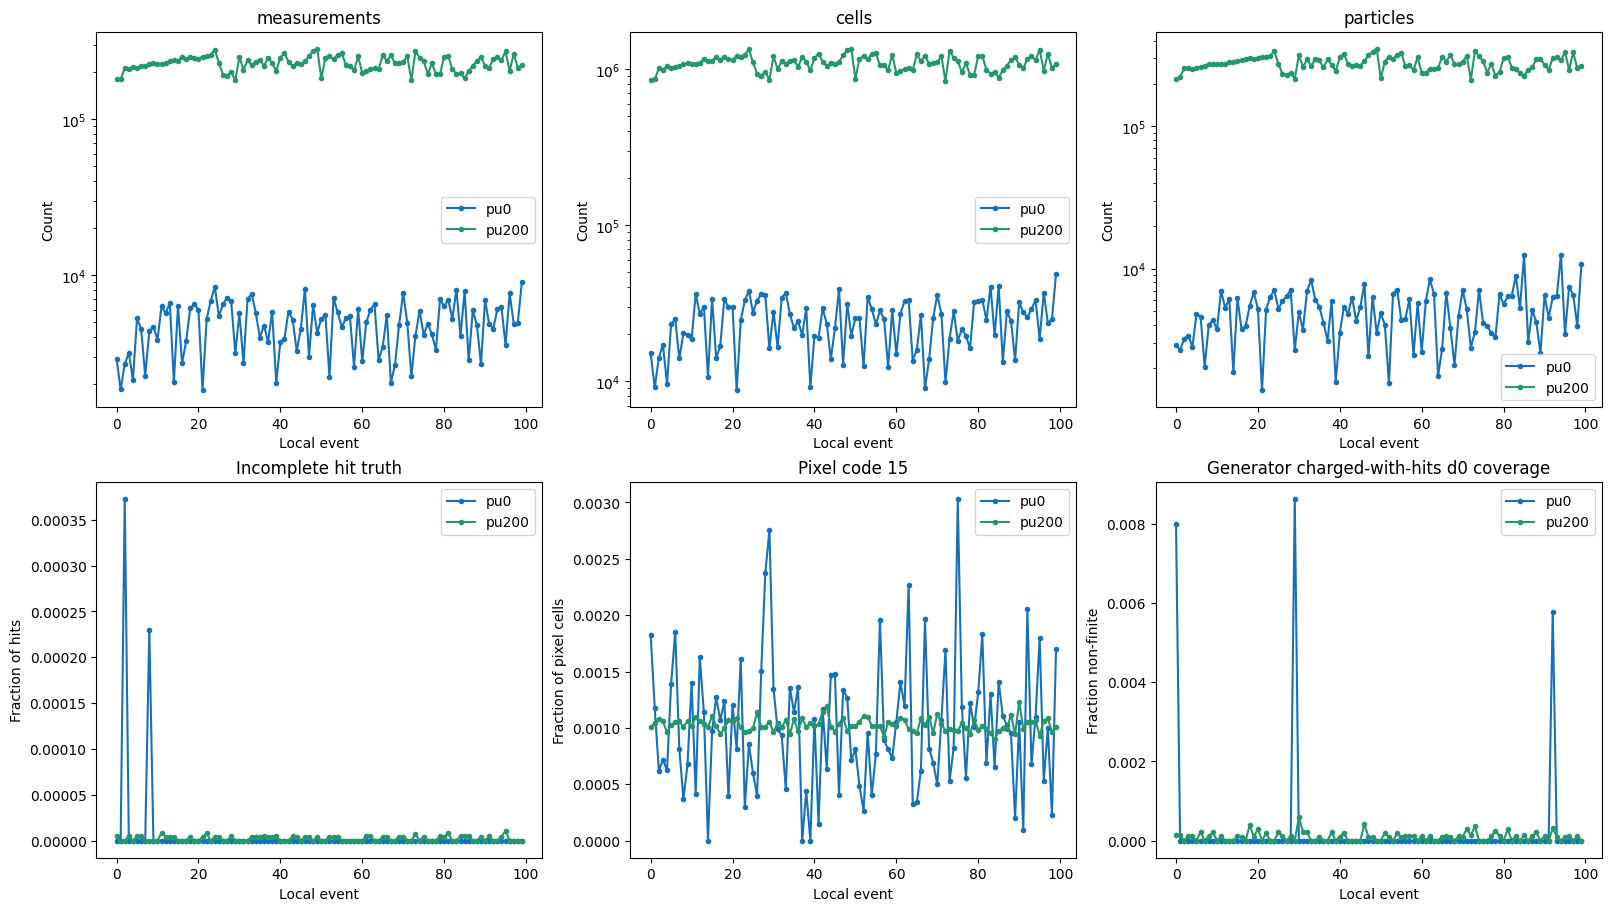

PASS: all-event associations and quantization reproduce the production reports.


In [11]:
campaign_scan = None
if RUN_FULL_SHARD_SCAN:
    campaign_scan = validation.scan_campaign(PAIRED_ROOT)
    event_counts = campaign_scan["counts"]
    display(event_counts.groupby("sample")[["measurements", "cells", "particles", "llps",
        "orphan_cells", "hits_without_cells", "missing_parent_ids", "unresolved_simhit_links",
        "incomplete_truth_measurements", "converted_label_disagreements"]].sum())
    display(event_counts)
    coverage_all = campaign_scan["perigees"].groupby(["sample", "cohort", "feature"])[
        ["particles", "finite", "nonfinite"]].sum()
    coverage_all["nonfinite_fraction"] = coverage_all.nonfinite / coverage_all.particles.replace(0, np.nan)
    display(coverage_all)
    display(campaign_scan["codes"])
    flagged_hits = campaign_scan["issues"]
    print("All flagged hits (complete scan):", len(flagged_hits))
    with pd.option_context("display.max_rows", 150, "display.max_colwidth", 80):
        display(flagged_hits)
    validation.plot_campaign(campaign_scan)
    print("PASS: all-event associations and quantization reproduce the production reports.")
else:
    print("Full-shard scan disabled: selected-event plots alone do not validate all 100 events.")

## Read-only confirmation and interpretation

The checks above establish file consistency, associations, feature availability, detector coverage and correct frozen encoding. They do **not** establish physical resolution, mass/lifetime reconstruction, downstream tracking efficiency, or event-matched pileup effects. Those require additional reconstruction and larger/matched samples.

Save this notebook after running it to retain figures and tables for review.

In [12]:
if CHECK_SOURCE_HASHES:
    after_hashes = validation.file_hashes(PAIRED_ROOT)
    assert before_hashes == after_hashes, "Source Parquet contents changed during analysis"
    print("PASS: all six source Parquet SHA256 checksums are unchanged")
else:
    print("Source checksum verification was disabled")
print("Validation cells completed; review warnings, missingness and legacy-label disagreements above.")

PASS: all six source Parquet SHA256 checksums are unchanged
Validation cells completed; review warnings, missingness and legacy-label disagreements above.


## Current stored truth-perigee validation

This section tests the **current `PAIRED_ROOT` Parquet files** against the independent reference for the same event. The original reference is hash-checked against `BASELINE_PAIRED_ROOT`; all non-perigee particle features must match that baseline before its reference is reused. Current ROOT writer provenance and its input checksum are also checked.

The reference uses SciPy DOP853 Lorentz integration in the queried ODD field, independently of ACTS's stepper. The chosen branch is the local transverse-distance minimum nearest production in absolute path length, searching both directions within a finite bound. These are numerical truth-parameter checks, not detector resolution measurements.

Under the recovery-only policy, all original finite perigees must remain exactly unchanged. New recoveries must agree with the independent reference. Known legacy reference discrepancies are reported as `legacy_mismatch_preserved`; unresolved values remain NaN. Residuals below use actual values from the current Parquets, not the older diagnostic candidates. ROOT does not store the propagation path length, so no current path residual is claimed.


**Optional historical check:** disabled by default for the 100-event release. Its baseline ROOT files and independent references cover only the original one-event pilot. Enabling it for this new release does not supply a valid independent numerical reference. The full-shard section above checks finite d0/z0 coverage, not their numerical accuracy.

In [13]:
if RUN_PERIGEE_REFERENCE:
    print("Current Parquet directory being tested:", PAIRED_ROOT)
    reference_summary, comparisons, uniform_checks, current_perigee_checks = validation.load_current_perigee_validation(
        samples, BASELINE_PAIRED_ROOT, PERIGEE_VALIDATION_ROOT)
    display(current_perigee_checks)
    display(pd.Series({key: reference_summary[key] for key in (
        "mode", "branch_convention", "reference", "input_precision", "tolerances_mm",
        "uniform_cases", "uniform_reference_pass", "source_files_unchanged")}).to_frame("Validation settings"))
    # These test the independent reference, not the old ACTS candidate outputs.
    display(uniform_checks[["case", "bz_T", "charge", "reference_pass",
                            "reference_delta_d0", "reference_delta_z0"]])
    display(validation.perigee_validation_statistics(comparisons))
    display(comparisons.loc[comparisons.status != "pass", [
        "sample", "particle_id", "pdg_id", "pt_GeV", "originally_finite",
        "method", "reference_status", "status", "candidate_d0", "candidate_z0",
        "delta_d0", "delta_z0"]])
else:
    print("Skipped: independent numerical perigee reference is specific to the original one-event pilot.")

Skipped: independent numerical perigee reference is specific to the original one-event pilot.


In [14]:
if RUN_PERIGEE_REFERENCE:
    validation.plot_perigee_validation(comparisons, reference_summary, value_label="Current stored perigee")
    display(comparisons.nlargest(10, "momentum_drift")[
        ["sample", "particle_id", "momentum_drift", "reference_curvature", "reference_status"]])
    checked = comparisons[comparisons.reference_converged.notna()]
    display(checked[["sample", "particle_id", "reference_converged", "refinement_levels",
                     "reference_delta_tighter_d0", "reference_delta_tighter_z0"]])
    assert reference_summary["source_files_unchanged"]
    if CHECK_SOURCE_HASHES:
        assert before_hashes == validation.file_hashes(PAIRED_ROOT)
    print("PASS: current Parquets tested; original finite perigees preserved; new recoveries validated; source files unchanged.")
else:
    print("Skipped: independent numerical perigee reference is specific to the original one-event pilot.")

Skipped: independent numerical perigee reference is specific to the original one-event pilot.
